# 04 - Exploratory Data Analysis

## Objective

Explore historical agricultural market prices across the 46 selected vegetables in India to understand price behaviour, reporting patterns, seasonal variation, volatility, and geographical differences.

## Objectives

1. Examine historical reporting coverage across commodities and markets.
2. Investigate changes in reporting activity and data availability.
3. Analyse historical vegetable price trends.
4. Identify recurring seasonal price patterns.
5. Examine price volatility and unusual price movements.
6. Explore geographical differences in wholesale prices.
7. Document significant data-quality findings and analytical limitations.

## Input

- `data/processed/vegetable_prices_cleaned.parquet`

## Scope

All 46 vegetables selected during Notebook 01 are included in the exploratory analysis.

The 39 commodities with qualifying forecasting candidates identified in Notebook 03 represent a separate subset used specifically for forecasting experiments.

## Important limitations

- The source dataset ends on 20 April 2026.
- Reporting activity declines substantially after October 2025.
- Wholesale modal prices should not be interpreted as guaranteed farmgate prices.
- Observed price patterns and associations do not establish causation.

---

# 1. Dataset Overview

Before conducting exploratory analysis, examine the structure, scale, temporal coverage, and geographical distribution of the cleaned dataset.

This section establishes the analytical scope and verifies that the dataset contains the expected 46 vegetables.

### Questions to investigate

- How many records are available?
- How many vegetables, states, districts, and markets are represented?
- What is the date range?
- How are observations distributed across vegetables?
- Are there substantial differences in the amount of historical data available for each vegetable?

In [1]:
# 1.1 Import libraries and connect to the cleaned dataset

from pathlib import Path

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Project paths
ROOT = Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"
DATA_FILE = PROCESSED_DIR / "vegetable_prices_cleaned.parquet"

# Verify that the dataset exists
if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

# Create DuckDB connection
eda_con = duckdb.connect()

# Create a view over the cleaned Parquet dataset
eda_con.execute(f"""
    CREATE OR REPLACE VIEW vegetable_prices AS
    SELECT *
    FROM read_parquet('{DATA_FILE.as_posix()}')
""")

print("Dataset loaded successfully.")
print(f"Dataset path: {DATA_FILE}")

Dataset loaded successfully.
Dataset path: c:\Users\Lenovo\Documents\GrittingCode\MandiMitra\data\processed\vegetable_prices_cleaned.parquet


In [2]:
# 1.2 Dataset overview statistics

overview = eda_con.execute("""
    SELECT
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT Project_Commodity) AS Total_Vegetables,
        COUNT(DISTINCT State) AS Total_States,
        COUNT(DISTINCT District) AS Total_Districts,
        COUNT(DISTINCT Market) AS Total_Markets,
        COUNT(DISTINCT Variety) AS Total_Varieties,
        COUNT(DISTINCT Grade) AS Total_Grades,
        MIN(Parsed_Date) AS First_Observation,
        MAX(Parsed_Date) AS Last_Observation
    FROM vegetable_prices
""").df()

display(overview)

,Total_Records,Total_Vegetables,Total_States,Total_Districts,Total_Markets,Total_Varieties,Total_Grades,First_Observation,Last_Observation
0,30336319,46,33,616,4475,137,14,2001-01-10,2026-04-20


In [3]:
# 1.3 Record distribution across vegetables

commodity_distribution = eda_con.execute("""
    SELECT
        Project_Commodity,
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT State) AS States_Covered,
        COUNT(DISTINCT (State, District, Market)) AS Market_Identities,
        MIN(Parsed_Date) AS First_Observation,
        MAX(Parsed_Date) AS Last_Observation
    FROM vegetable_prices
    GROUP BY Project_Commodity
    ORDER BY Total_Records DESC
""").df()

commodity_distribution["Record_Share_Percent"] = (
    commodity_distribution["Total_Records"]
    / commodity_distribution["Total_Records"].sum()
    * 100
).round(2)

display(commodity_distribution)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Project_Commodity,Total_Records,States_Covered,Market_Identities,First_Observation,Last_Observation,Record_Share_Percent
0,Potato,3248774,33,2990,2001-01-10,2026-04-20,10.71
1,Onion,3168401,32,3223,2001-01-10,2026-04-20,10.44
2,Tomato,2818498,32,3075,2001-02-08,2026-04-20,9.29
3,Brinjal,2448357,31,2897,2001-01-27,2026-04-20,8.07
4,Green Chilli,2107918,31,2834,2001-03-12,2026-04-20,6.95
5,Cauliflower,1701542,33,2397,2001-01-27,2026-04-20,5.61
6,Bhindi (Ladies Finger),1571994,31,2493,2001-04-08,2026-04-20,5.18
7,Cabbage,1505826,33,2572,2001-11-22,2026-04-20,4.96
8,Bottle gourd,1214983,31,2083,2001-04-12,2026-04-20,4.01
9,Bitter gourd,1181866,32,2389,2001-04-21,2026-04-20,3.90


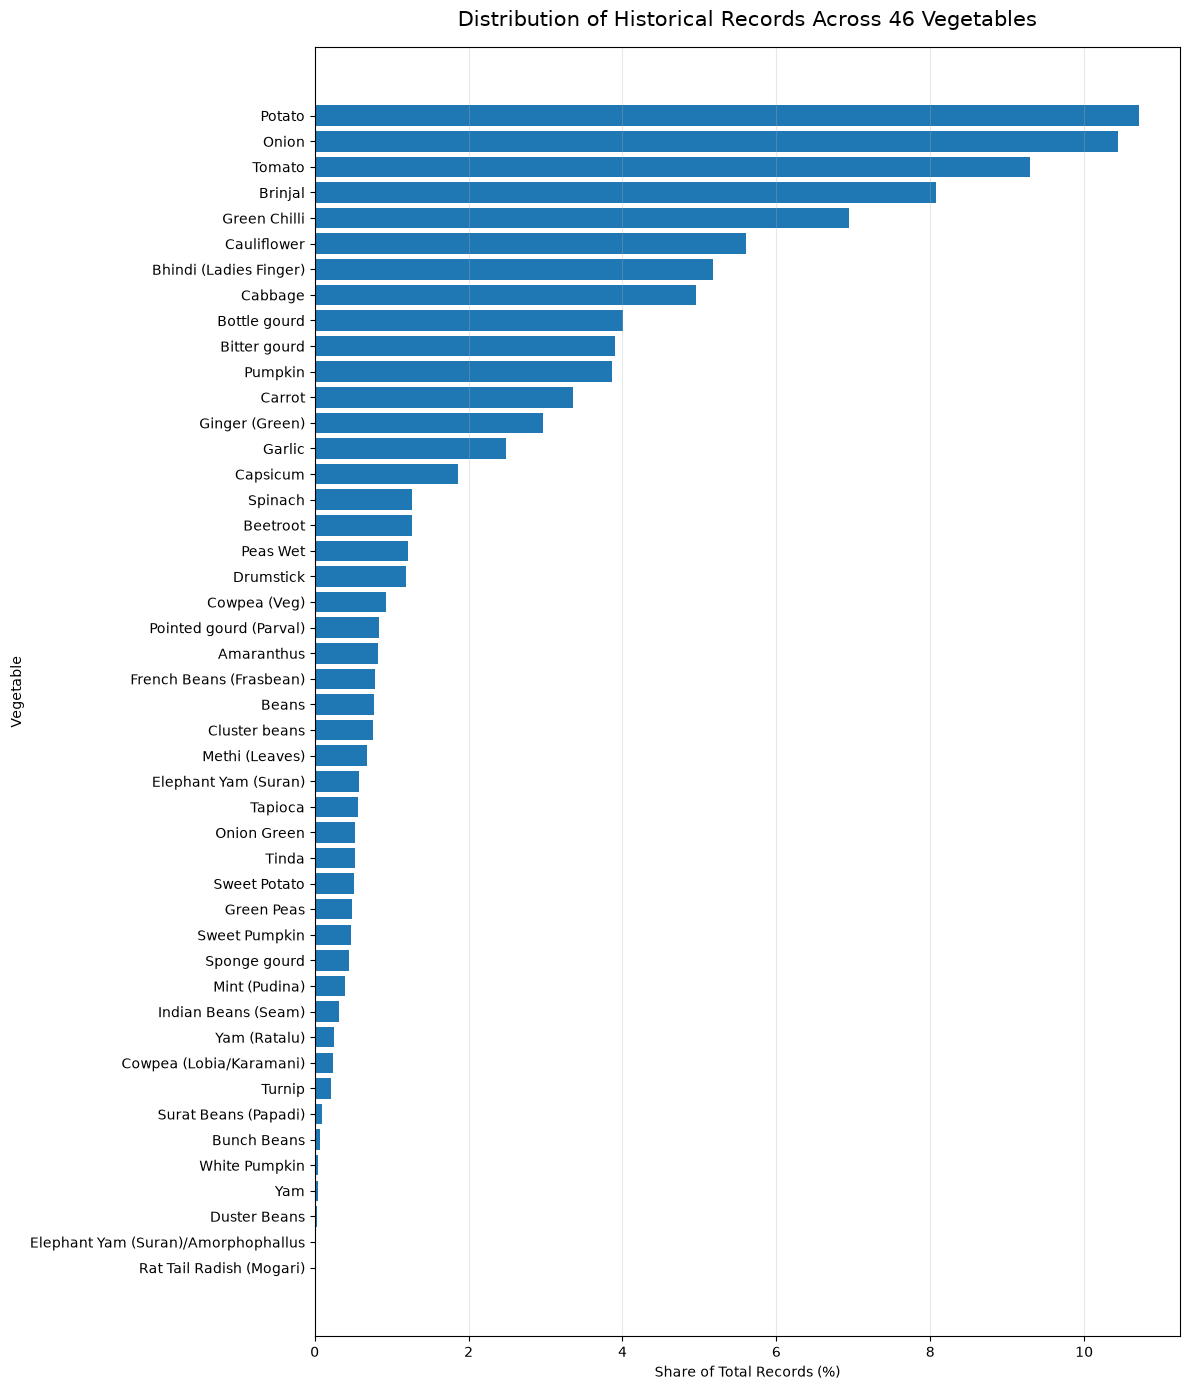

In [4]:
# 1.4 Visualise record distribution across vegetables

plt.figure(figsize=(12, 14))

plt.barh(
    commodity_distribution["Project_Commodity"][::-1],
    commodity_distribution["Record_Share_Percent"][::-1]
)

plt.title(
    "Distribution of Historical Records Across 46 Vegetables",
    fontsize=15,
    pad=15
)

plt.xlabel("Share of Total Records (%)")
plt.ylabel("Vegetable")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 1.5 Historical Coverage Across Vegetables

The total number of records does not reveal whether observations are consistently distributed across the historical period.

This analysis examines the first and last reporting dates and the number of calendar months in which each vegetable has recorded observations.

It helps identify vegetables with limited historical coverage or incomplete reporting periods.

In [5]:
# 1.5 Historical coverage across vegetables

coverage = eda_con.execute("""
    SELECT
        Project_Commodity,
        COUNT(DISTINCT DATE_TRUNC('month', Parsed_Date)) AS Active_Months,
        DATE_DIFF(
            'month',
            DATE_TRUNC('month', MIN(Parsed_Date)),
            DATE_TRUNC('month', MAX(Parsed_Date))
        ) + 1 AS Possible_Months,
        MIN(Parsed_Date) AS First_Observation,
        MAX(Parsed_Date) AS Last_Observation
    FROM vegetable_prices
    GROUP BY Project_Commodity
""").df()

coverage["Monthly_Coverage_Percent"] = (
    coverage["Active_Months"]
    / coverage["Possible_Months"]
    * 100
).round(2)

coverage = coverage.sort_values(
    "Monthly_Coverage_Percent",
    ascending=True
)

display(coverage)

,Project_Commodity,Active_Months,Possible_Months,First_Observation,Last_Observation,Monthly_Coverage_Percent
27,Rat Tail Radish (Mogari),177,277,2003-03-14,2026-03-10,63.90
14,Duster Beans,270,287,2002-06-19,2026-04-20,94.08
41,Sponge gourd,265,277,2003-04-12,2026-04-20,95.67
43,Mint (Pudina),265,277,2003-04-02,2026-04-20,95.67
45,Turnip,254,264,2004-05-08,2026-04-20,96.21
42,Tinda,268,277,2003-04-02,2026-04-20,96.75
6,Onion Green,263,271,2003-10-11,2026-04-20,97.05
5,Yam,267,274,2003-07-23,2026-04-20,97.45
8,Tapioca,274,280,2003-01-03,2026-04-20,97.86
3,Cluster beans,295,301,2001-04-07,2026-04-20,98.01


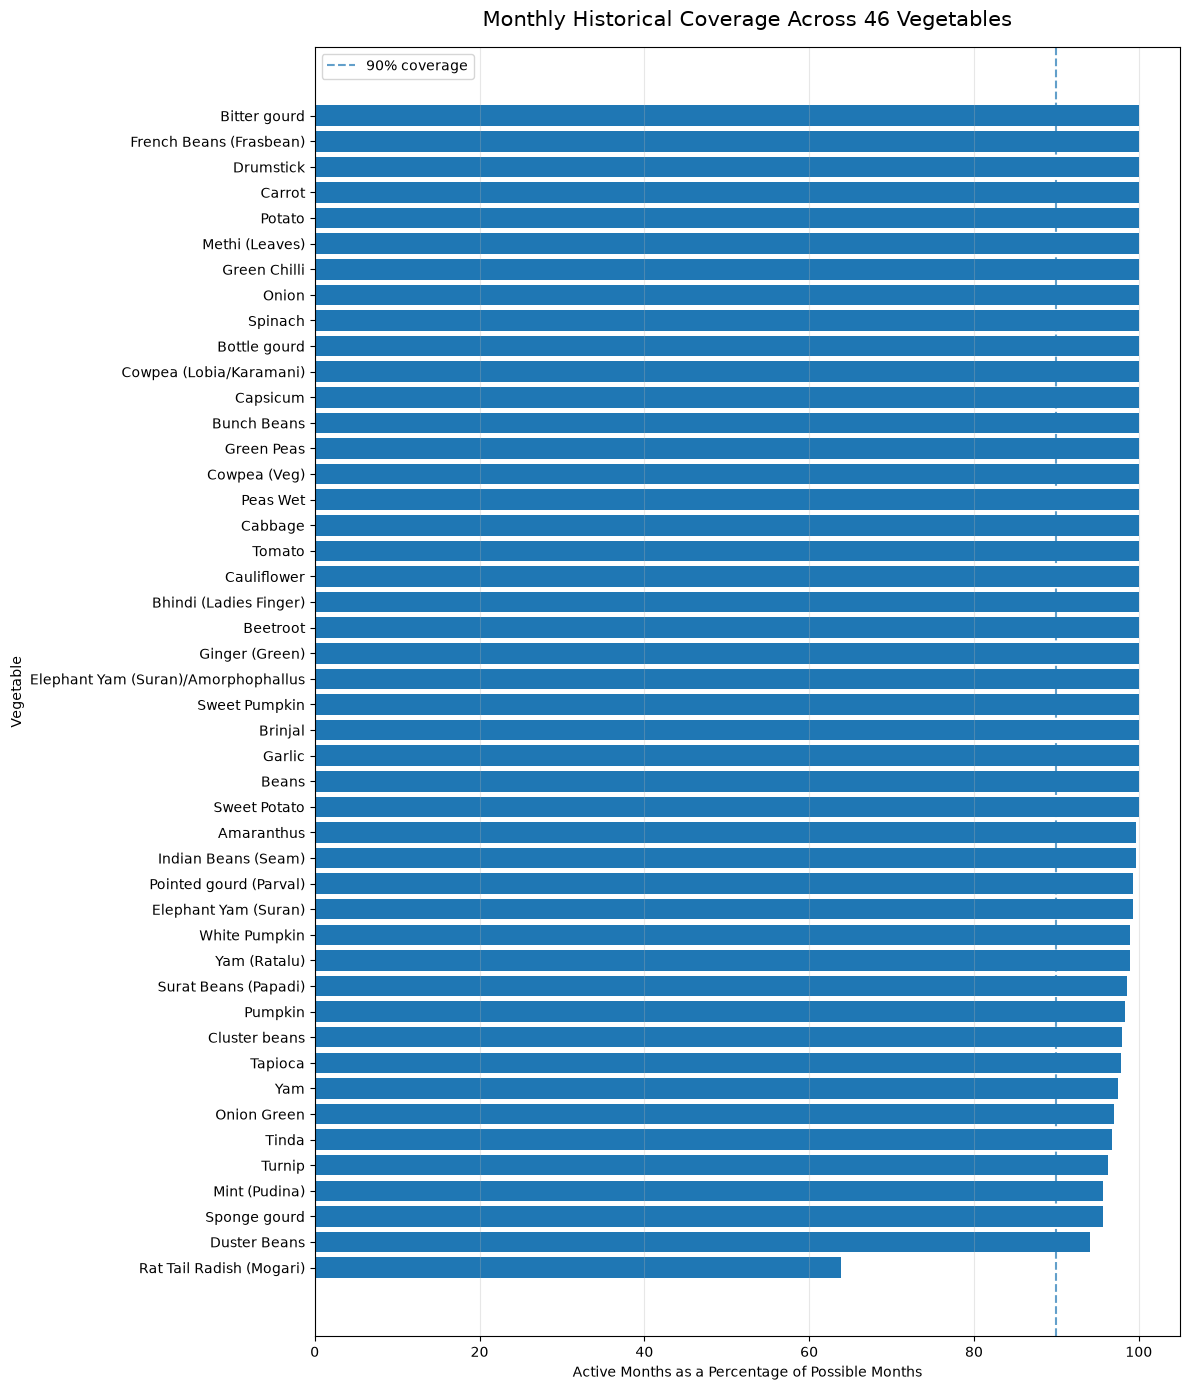

In [6]:
# 1.6 Visualise monthly coverage across vegetables

coverage_plot = coverage.sort_values(
    "Monthly_Coverage_Percent",
    ascending=True
)

plt.figure(figsize=(12, 14))

plt.barh(
    coverage_plot["Project_Commodity"],
    coverage_plot["Monthly_Coverage_Percent"]
)

plt.axvline(
    90,
    linestyle="--",
    alpha=0.7,
    label="90% coverage"
)

plt.title(
    "Monthly Historical Coverage Across 46 Vegetables",
    fontsize=15,
    pad=15
)

plt.xlabel("Active Months as a Percentage of Possible Months")
plt.ylabel("Vegetable")
plt.xlim(0, 105)
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

---

# 2. Reporting Activity Over Time

The reliability of historical market analysis depends partly on the consistency of data reporting.

This section examines changes in reporting activity across the 46 selected vegetables, with particular attention to the decline in reported observations after October 2025.

### Questions to investigate

- How has the number of reported price observations changed over time?
- How many distinct markets report prices each month?
- Is the decline in reporting activity visible across the dataset?
- Does the decline affect all vegetables similarly?

In [7]:
# 2.1 Calculate monthly reporting activity

monthly_reporting = eda_con.execute("""
    SELECT
        DATE_TRUNC('month', Parsed_Date) AS Month,
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT (State, District, Market)) AS Active_Markets,
        COUNT(DISTINCT Project_Commodity) AS Active_Vegetables
    FROM vegetable_prices
    GROUP BY DATE_TRUNC('month', Parsed_Date)
    ORDER BY Month
""").df()

display(monthly_reporting.tail(20))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Month,Total_Records,Active_Markets,Active_Vegetables
284,2024-09-01,279248,1458,45
285,2024-10-01,284840,1460,45
286,2024-11-01,269907,1444,45
287,2024-12-01,287142,1467,45
288,2025-01-01,297362,1471,45
289,2025-02-01,280201,1462,45
290,2025-03-01,297032,1464,45
291,2025-04-01,292751,1461,45
292,2025-05-01,298784,1485,44
293,2025-06-01,281684,1483,45


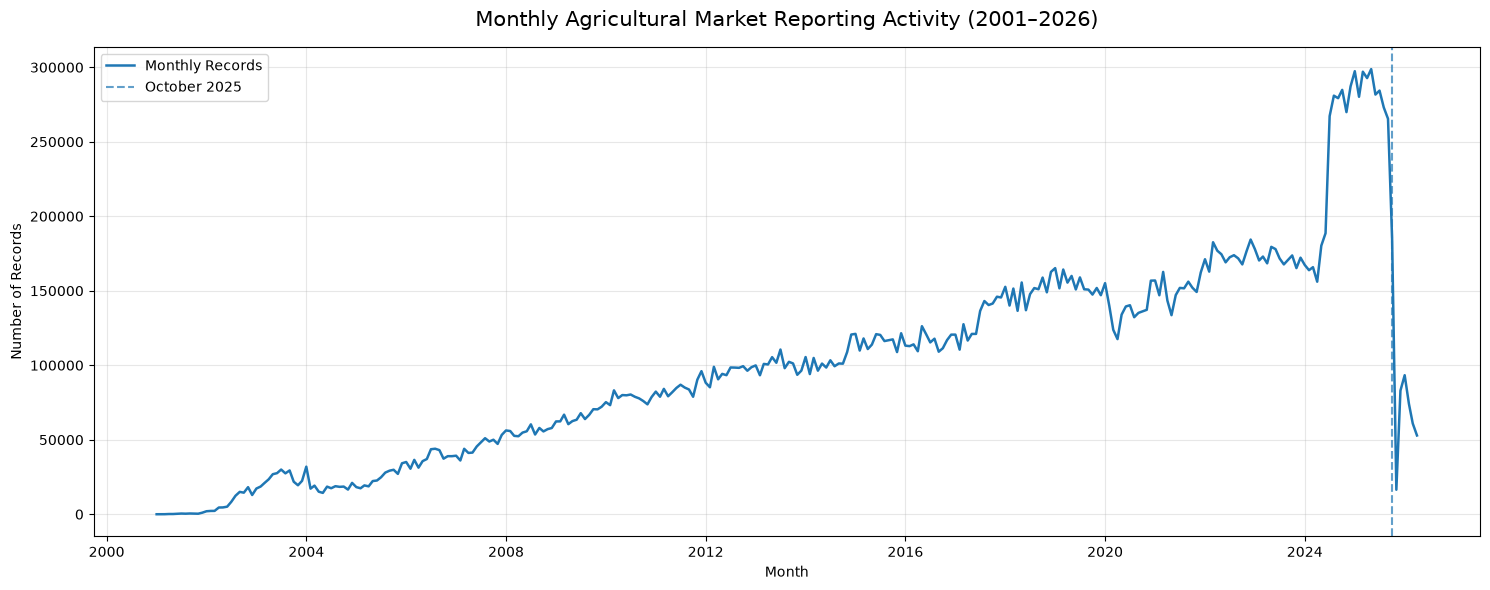

In [8]:
# 2.2 Visualise monthly reporting activity

fig, ax1 = plt.subplots(figsize=(15, 6))

ax1.plot(
    monthly_reporting["Month"],
    monthly_reporting["Total_Records"],
    linewidth=1.8,
    label="Monthly Records"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Number of Records")
ax1.set_title(
    "Monthly Agricultural Market Reporting Activity (2001–2026)",
    fontsize=15,
    pad=15
)

ax1.axvline(
    pd.Timestamp("2025-10-01"),
    linestyle="--",
    alpha=0.7,
    label="October 2025"
)

ax1.grid(alpha=0.3)
ax1.legend()
plt.tight_layout()
plt.show()

### 2.3 Commodity-wise Reporting Decline

The overall reporting trend may conceal differences between individual vegetables.

This analysis compares monthly reporting volumes during two periods:

- **Baseline:** November 2024 to October 2025
- **Post-disruption:** November 2025 to October 2026

Since the dataset ends on 20 April 2026, the post-disruption period is incomplete. Therefore, the comparison will use only November 2025 to March 2026, excluding the incomplete April 2026 observations.

For a fair comparison, the baseline will use the corresponding five calendar months from November 2024 to March 2025.

In [9]:
# 2.3 Compare commodity-wise reporting volumes

commodity_reporting = eda_con.execute("""
    SELECT
        Project_Commodity,

        SUM(
            CASE
                WHEN Parsed_Date >= DATE '2024-11-01'
                 AND Parsed_Date < DATE '2025-04-01'
                THEN 1 ELSE 0
            END
        ) AS Baseline_Records,

        SUM(
            CASE
                WHEN Parsed_Date >= DATE '2025-11-01'
                 AND Parsed_Date < DATE '2026-04-01'
                THEN 1 ELSE 0
            END
        ) AS Post_Disruption_Records

    FROM vegetable_prices
    GROUP BY Project_Commodity
""").df()

commodity_reporting["Baseline_Monthly_Avg"] = (
    commodity_reporting["Baseline_Records"] / 5
)

commodity_reporting["Post_Monthly_Avg"] = (
    commodity_reporting["Post_Disruption_Records"] / 5
)

commodity_reporting["Reporting_Change_Percent"] = (
    (
        commodity_reporting["Post_Monthly_Avg"]
        - commodity_reporting["Baseline_Monthly_Avg"]
    )
    / commodity_reporting["Baseline_Monthly_Avg"]
    * 100
).replace([np.inf, -np.inf], np.nan).round(2)

commodity_reporting = commodity_reporting.sort_values(
    "Reporting_Change_Percent"
)

display(commodity_reporting)

,Project_Commodity,Baseline_Records,Post_Disruption_Records,Baseline_Monthly_Avg,Post_Monthly_Avg,Reporting_Change_Percent
28,Elephant Yam (Suran),19243.0,194.0,3848.6,38.8,-98.99
42,Amaranthus,30869.0,356.0,6173.8,71.2,-98.85
38,Yam,280.0,18.0,56.0,3.6,-93.57
0,Pointed gourd (Parval),3820.0,590.0,764.0,118.0,-84.55
3,Cowpea (Lobia/Karamani),1604.0,261.0,320.8,52.2,-83.73
16,Sponge gourd,1431.0,241.0,286.2,48.2,-83.16
37,White Pumpkin,232.0,42.0,46.4,8.4,-81.90
13,Potato,106189.0,20392.0,21237.8,4078.4,-80.80
10,Spinach,15872.0,3125.0,3174.4,625.0,-80.31
20,Tomato,106721.0,21056.0,21344.2,4211.2,-80.27


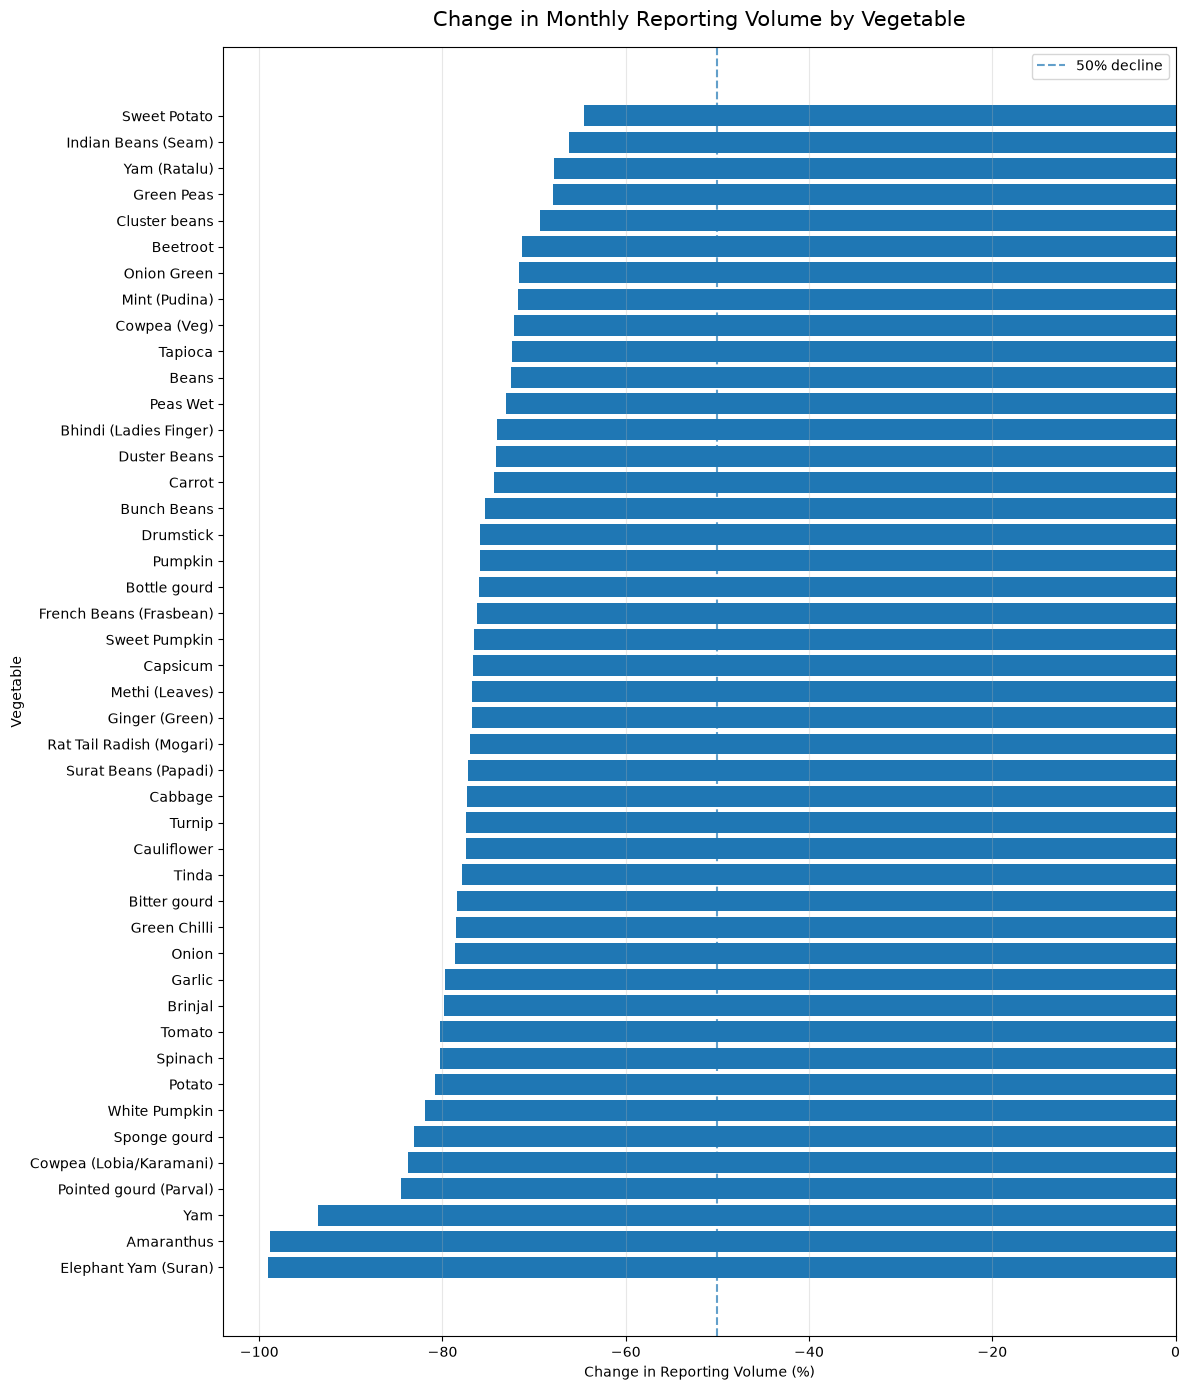

In [10]:
# 2.4 Visualise commodity-wise reporting changes

plot_data = commodity_reporting.dropna(
    subset=["Reporting_Change_Percent"]
).sort_values("Reporting_Change_Percent")

plt.figure(figsize=(12, 14))

plt.barh(
    plot_data["Project_Commodity"],
    plot_data["Reporting_Change_Percent"]
)

plt.axvline(
    -50,
    linestyle="--",
    alpha=0.7,
    label="50% decline"
)

plt.title(
    "Change in Monthly Reporting Volume by Vegetable",
    fontsize=15,
    pad=15
)

plt.xlabel("Change in Reporting Volume (%)")
plt.ylabel("Vegetable")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 2.5 Market Participation vs Reporting Frequency

A decline in total records can occur because fewer markets report prices, because existing markets report less frequently, or because of both factors.

This analysis compares:

- The number of distinct market identities reporting each month.
- The average number of records contributed by each active market.

The comparison uses November 2024–March 2025 as the baseline and November 2025–March 2026 as the post-disruption period.

In [11]:
# 2.5 Compare market participation and reporting frequency

period_comparison = eda_con.execute("""
    SELECT
        CASE
            WHEN Parsed_Date >= DATE '2024-11-01'
             AND Parsed_Date < DATE '2025-04-01'
            THEN 'Baseline'
            WHEN Parsed_Date >= DATE '2025-11-01'
             AND Parsed_Date < DATE '2026-04-01'
            THEN 'Post-Disruption'
        END AS Period,

        COUNT(*) AS Total_Records,

        COUNT(DISTINCT (State, District, Market))
            AS Active_Markets

    FROM vegetable_prices

    WHERE (
        Parsed_Date >= DATE '2024-11-01'
        AND Parsed_Date < DATE '2025-04-01'
    )
    OR (
        Parsed_Date >= DATE '2025-11-01'
        AND Parsed_Date < DATE '2026-04-01'
    )

    GROUP BY Period
    ORDER BY Period
""").df()

period_comparison["Records_Per_Active_Market"] = (
    period_comparison["Total_Records"]
    / period_comparison["Active_Markets"]
).round(2)

display(period_comparison)

,Period,Total_Records,Active_Markets,Records_Per_Active_Market
0,Baseline,1431644,1616,885.92
1,Post-Disruption,327836,2775,118.14


In [12]:
# 2.6 Compare reporting activity using market-months

market_month_comparison = eda_con.execute("""
    WITH monthly_activity AS (
        SELECT
            DATE_TRUNC('month', Parsed_Date) AS Month,
            COUNT(*) AS Total_Records,
            COUNT(DISTINCT (State, District, Market))
                AS Active_Markets
        FROM vegetable_prices
        WHERE (
            Parsed_Date >= DATE '2024-11-01'
            AND Parsed_Date < DATE '2025-04-01'
        )
        OR (
            Parsed_Date >= DATE '2025-11-01'
            AND Parsed_Date < DATE '2026-04-01'
        )
        GROUP BY DATE_TRUNC('month', Parsed_Date)
    )

    SELECT
        CASE
            WHEN Month < DATE '2025-04-01'
            THEN 'Baseline'
            ELSE 'Post-Disruption'
        END AS Period,

        SUM(Total_Records) AS Total_Records,
        SUM(Active_Markets) AS Total_Market_Months,
        AVG(Active_Markets) AS Average_Active_Markets_Per_Month

    FROM monthly_activity
    GROUP BY Period
    ORDER BY Period
""").df()

market_month_comparison["Records_Per_Market_Month"] = (
    market_month_comparison["Total_Records"]
    / market_month_comparison["Total_Market_Months"]
).round(2)

display(market_month_comparison)

,Period,Total_Records,Total_Market_Months,Average_Active_Markets_Per_Month,Records_Per_Market_Month
0,Baseline,1431644.0,7308.0,1461.6,195.90
1,Post-Disruption,327836.0,6840.0,1368.0,47.93


### 2.7 Reporting Disruption: Key Findings

The analysis identifies a substantial decline in agricultural market reporting after October 2025.

Comparing November 2024–March 2025 with November 2025–March 2026:

- Total records declined by approximately 77.1%.
- Average active market identities per month declined by approximately 6.4%.
- Records per active market-month declined by approximately 75.5%.
- Reporting declines were observed across nearly all selected vegetables.

The results suggest that reduced reporting frequency and/or reduced commodity coverage within reporting markets contributed substantially to the decline.

**Analytical implication:** Historical price patterns remain useful for exploratory analysis, but recent observations have substantially weaker reporting coverage. Any market comparison or forecasting result must account for this limitation.

The analysis cannot establish why reporting declined or whether the underlying physical markets became less active.

---

# 3. Historical Price Trends

This section examines how wholesale modal prices have changed over time across the 46 selected vegetables.

Monthly median prices are used to reduce the influence of extreme individual observations.

The analysis also tracks the number of records and reporting markets contributing to each monthly estimate, since changes in reporting coverage can affect the observed price distribution.

### Questions to investigate

- How have wholesale prices changed over the historical period?
- Which vegetables show substantial long-term price movements?
- How do price patterns differ across vegetables?
- How should changes in reporting coverage affect the interpretation of historical trends?

In [13]:
# 3.1 Calculate monthly median prices across vegetables

monthly_prices = eda_con.execute("""
    SELECT
        Project_Commodity,
        DATE_TRUNC('month', Parsed_Date) AS Month,
        MEDIAN(Modal_Price) AS Median_Modal_Price,
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT (State, District, Market)) AS Active_Markets

    FROM vegetable_prices

    GROUP BY
        Project_Commodity,
        DATE_TRUNC('month', Parsed_Date)

    ORDER BY
        Project_Commodity,
        Month
""").df()

print("Monthly price dataset shape:", monthly_prices.shape)
print(
    "Date range:",
    monthly_prices["Month"].min(),
    "to",
    monthly_prices["Month"].max()
)
print(
    "Vegetables represented:",
    monthly_prices["Project_Commodity"].nunique()
)

display(monthly_prices.head(10))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Monthly price dataset shape: (12871, 5)
Date range: 2001-01-01 00:00:00 to 2026-04-01 00:00:00
Vegetables represented: 46


,Project_Commodity,Month,Median_Modal_Price,Total_Records,Active_Markets
0,Amaranthus,2001-11-01,175.0,4,1
1,Amaranthus,2001-12-01,225.0,12,1
2,Amaranthus,2002-01-01,300.0,9,2
3,Amaranthus,2002-02-01,350.0,16,1
4,Amaranthus,2002-03-01,300.0,6,1
5,Amaranthus,2002-04-01,450.0,22,1
6,Amaranthus,2002-05-01,312.5,20,1
7,Amaranthus,2002-06-01,450.0,19,1
8,Amaranthus,2002-07-01,450.0,20,1
9,Amaranthus,2002-08-01,275.0,1,1


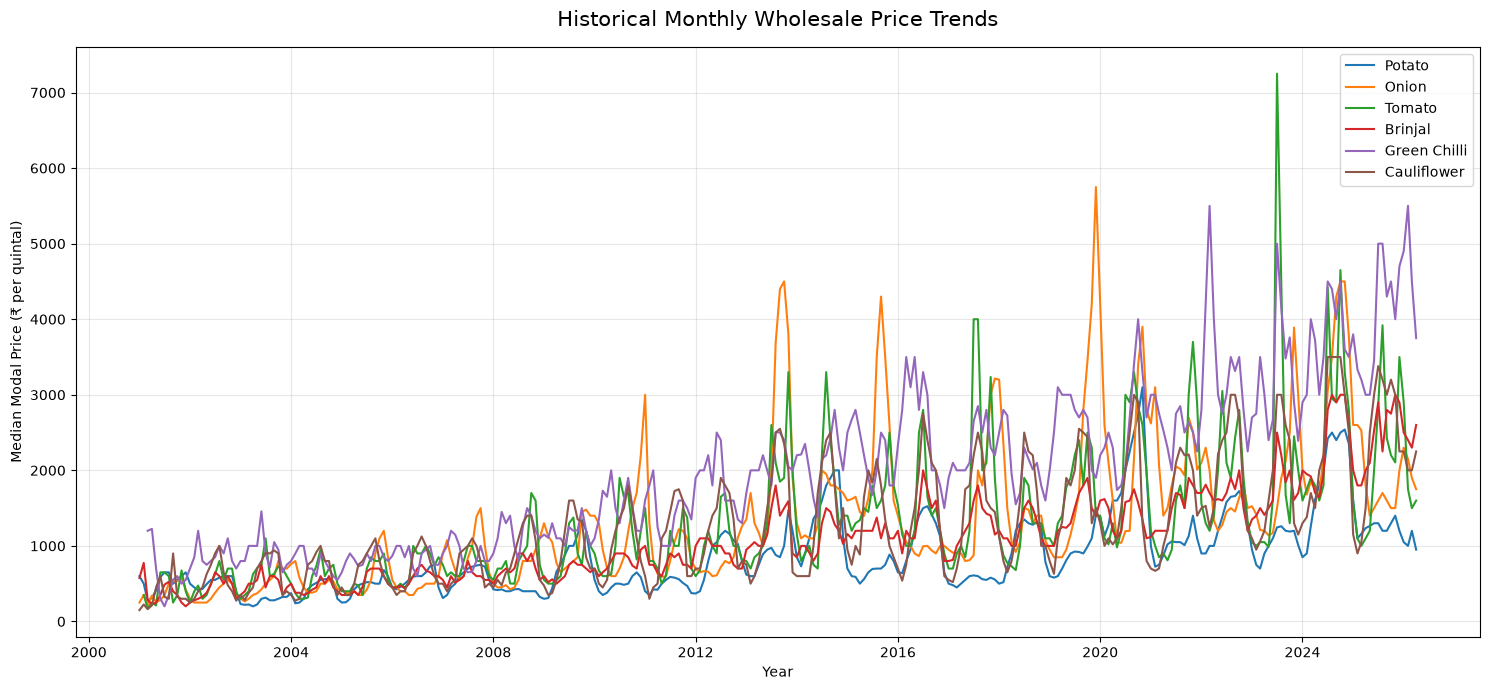

In [14]:
# 3.2 Visualise monthly price trends for major vegetables

selected_vegetables = [
    "Potato",
    "Onion",
    "Tomato",
    "Brinjal",
    "Green Chilli",
    "Cauliflower"
]

plt.figure(figsize=(15, 7))

for vegetable in selected_vegetables:
    subset = monthly_prices[
        monthly_prices["Project_Commodity"] == vegetable
    ]

    plt.plot(
        subset["Month"],
        subset["Median_Modal_Price"],
        label=vegetable,
        linewidth=1.5
    )

plt.title(
    "Historical Monthly Wholesale Price Trends",
    fontsize=15,
    pad=15
)

plt.xlabel("Year")
plt.ylabel("Median Modal Price (₹ per quintal)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

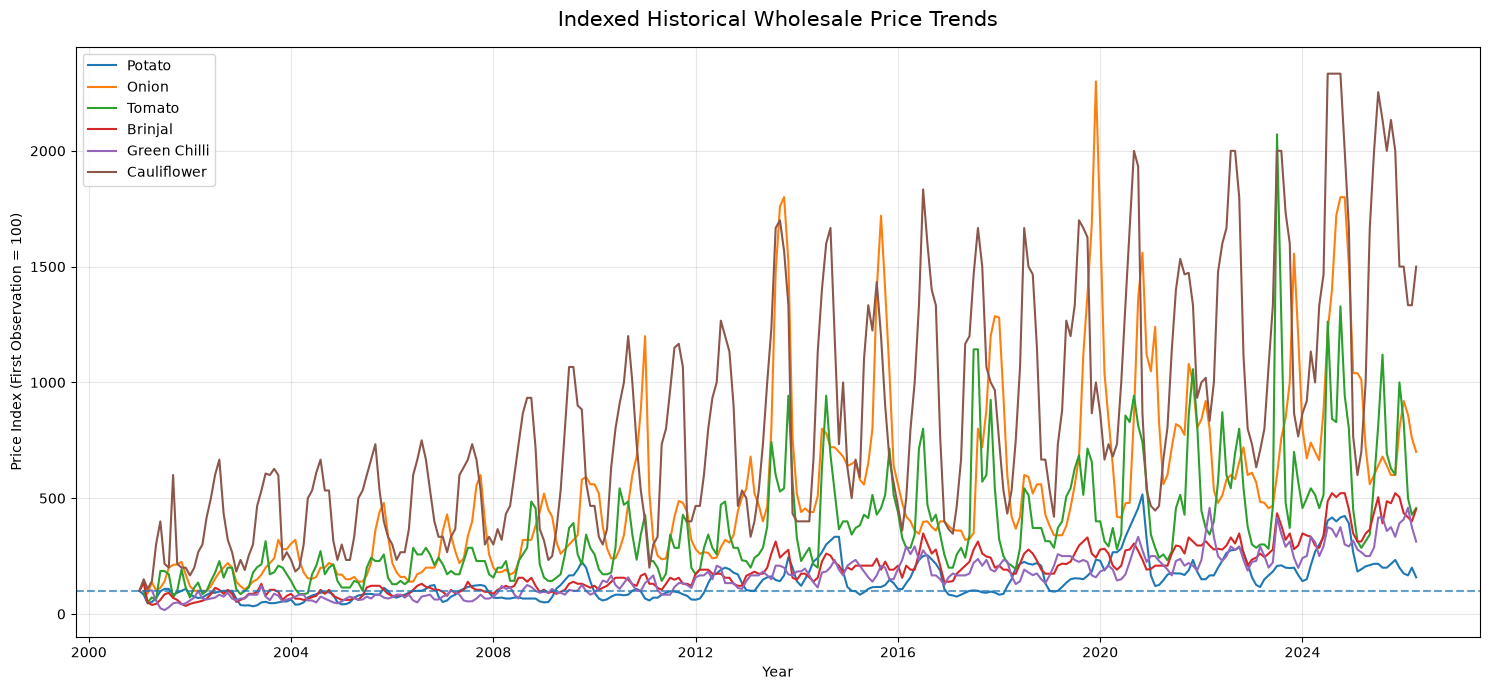

In [15]:
# 3.3 Compare relative price movements using an indexed trend

indexed_prices = monthly_prices.copy()

indexed_prices["Price_Index"] = (
    indexed_prices["Median_Modal_Price"]
    / indexed_prices.groupby("Project_Commodity")[
        "Median_Modal_Price"
    ].transform("first")
    * 100
)

plt.figure(figsize=(15, 7))

for vegetable in selected_vegetables:
    subset = indexed_prices[
        indexed_prices["Project_Commodity"] == vegetable
    ]

    plt.plot(
        subset["Month"],
        subset["Price_Index"],
        label=vegetable,
        linewidth=1.5
    )

plt.axhline(100, linestyle="--", alpha=0.7)

plt.title(
    "Indexed Historical Wholesale Price Trends",
    fontsize=15,
    pad=15
)

plt.xlabel("Year")
plt.ylabel("Price Index (First Observation = 100)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
# 3.4 Summarise long-term price changes by vegetable

price_change_summary = (
    monthly_prices
    .sort_values(["Project_Commodity", "Month"])
    .groupby("Project_Commodity")
    .agg(
        First_Month=("Month", "first"),
        Last_Month=("Month", "last"),
        First_Median_Price=("Median_Modal_Price", "first"),
        Last_Median_Price=("Median_Modal_Price", "last"),
        Monthly_Observations=("Median_Modal_Price", "count")
    )
    .reset_index()
)

price_change_summary["Price_Change_Percent"] = (
    (
        price_change_summary["Last_Median_Price"]
        - price_change_summary["First_Median_Price"]
    )
    / price_change_summary["First_Median_Price"]
    * 100
).round(2)

display(
    price_change_summary.sort_values(
        "Price_Change_Percent",
        ascending=False
    )
)

,Project_Commodity,First_Month,Last_Month,First_Median_Price,Last_Median_Price,Monthly_Observations,Price_Change_Percent
17,Elephant Yam (Suran),2002-08-01,2025-11-01,90.0,5000.0,278,5455.56
24,Indian Beans (Seam),2002-08-01,2026-04-01,180.0,5500.0,284,2955.56
30,Pointed gourd (Parval),2002-08-01,2026-04-01,200.0,4700.0,283,2250.00
0,Amaranthus,2001-11-01,2025-11-01,175.0,3000.0,288,1614.29
11,Cauliflower,2001-01-01,2026-04-01,150.0,2250.0,304,1400.00
7,Bunch Beans,2002-04-01,2026-04-01,450.0,5000.0,289,1011.11
42,Turnip,2004-05-01,2026-04-01,375.0,4000.0,254,966.67
25,Methi (Leaves),2001-11-01,2026-04-01,150.0,1500.0,294,900.00
37,Sweet Potato,2001-11-01,2026-04-01,325.0,3200.0,294,884.62
36,Surat Beans (Papadi),2002-08-01,2026-04-01,600.0,5000.0,281,733.33


In [17]:
# 3.5 Compare median prices across two five-year periods

period_prices = eda_con.execute("""
    SELECT
        Project_Commodity,

        MEDIAN(
            CASE
                WHEN Parsed_Date >= DATE '2001-01-01'
                 AND Parsed_Date < DATE '2006-01-01'
                THEN Modal_Price
            END
        ) AS Early_Period_Median,

        MEDIAN(
            CASE
                WHEN Parsed_Date >= DATE '2021-01-01'
                 AND Parsed_Date < DATE '2026-01-01'
                THEN Modal_Price
            END
        ) AS Recent_Period_Median,

        COUNT(
            CASE
                WHEN Parsed_Date >= DATE '2001-01-01'
                 AND Parsed_Date < DATE '2006-01-01'
                THEN 1
            END
        ) AS Early_Period_Records,

        COUNT(
            CASE
                WHEN Parsed_Date >= DATE '2021-01-01'
                 AND Parsed_Date < DATE '2026-01-01'
                THEN 1
            END
        ) AS Recent_Period_Records

    FROM vegetable_prices
    GROUP BY Project_Commodity
""").df()

period_prices["Price_Change_Percent"] = (
    (
        period_prices["Recent_Period_Median"]
        - period_prices["Early_Period_Median"]
    )
    / period_prices["Early_Period_Median"]
    * 100
).round(2)

display(
    period_prices.sort_values(
        "Price_Change_Percent",
        ascending=False
    )
)

,Project_Commodity,Early_Period_Median,Recent_Period_Median,Early_Period_Records,Recent_Period_Records,Price_Change_Percent
10,Onion Green,425.0,4600.0,631,105795,982.35
9,Yam,500.0,5200.0,373,1806,940.00
17,Sweet Potato,375.0,3000.0,4651,67946,700.00
21,Beetroot,420.0,3300.0,6812,192711,685.71
20,Elephant Yam (Suran),700.0,5300.0,2154,93623,657.14
18,Beans,800.0,5750.0,7332,118816,618.75
23,Duster Beans,800.0,5600.0,298,4157,600.00
4,Amaranthus,450.0,3000.0,1900,145857,566.67
1,Tapioca,470.0,3000.0,194,99261,538.30
3,Drumstick,900.0,5500.0,3262,177922,511.11


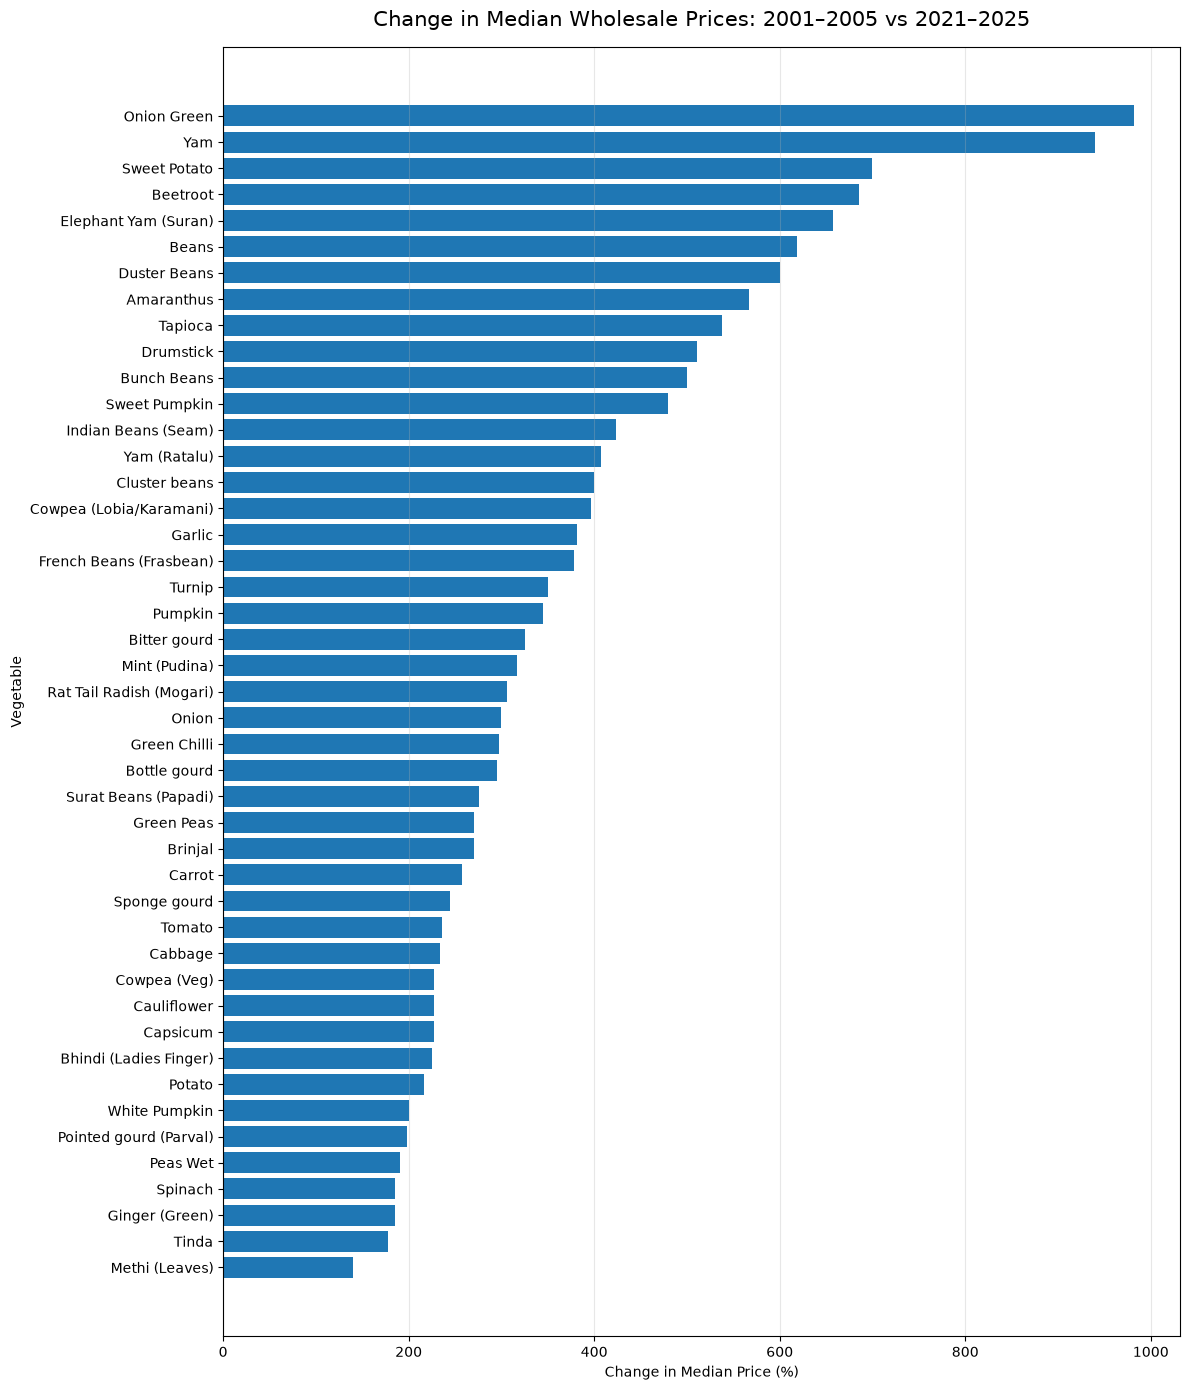

In [18]:
# 3.6 Visualise price differences between historical periods

plot_period_prices = period_prices.dropna(
    subset=["Price_Change_Percent"]
).sort_values("Price_Change_Percent")

plt.figure(figsize=(12, 14))

plt.barh(
    plot_period_prices["Project_Commodity"],
    plot_period_prices["Price_Change_Percent"]
)

plt.title(
    "Change in Median Wholesale Prices: 2001–2005 vs 2021–2025",
    fontsize=15,
    pad=15
)

plt.xlabel("Change in Median Price (%)")
plt.ylabel("Vegetable")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 3.7 Matched-Market Price Comparison

The previous comparison used all available observations, which means changes in market participation could influence the results.

This analysis reduces that limitation by comparing the same market identities across both periods.

For each vegetable, only markets with observations in both 2001–2005 and 2021–2025 are retained.

The comparison uses each market's median modal price within each period, followed by the median percentage change across matched markets.

This provides a more comparable view of historical price differences, although it does not adjust for inflation or changes in variety and grade composition.

In [19]:
# 3.7 Compare prices across consistently reporting markets

matched_market_prices = eda_con.execute("""
    WITH market_period_prices AS (
        SELECT
            Project_Commodity,
            State,
            District,
            Market,

            MEDIAN(
                CASE
                    WHEN Parsed_Date >= DATE '2001-01-01'
                     AND Parsed_Date < DATE '2006-01-01'
                    THEN Modal_Price
                END
            ) AS Early_Median,

            MEDIAN(
                CASE
                    WHEN Parsed_Date >= DATE '2021-01-01'
                     AND Parsed_Date < DATE '2026-01-01'
                    THEN Modal_Price
                END
            ) AS Recent_Median

        FROM vegetable_prices

        GROUP BY
            Project_Commodity,
            State,
            District,
            Market
    ),

    matched AS (
        SELECT *
        FROM market_period_prices
        WHERE Early_Median IS NOT NULL
          AND Recent_Median IS NOT NULL
          AND Early_Median > 0
    )

    SELECT
        Project_Commodity,
        COUNT(*) AS Matched_Markets,
        MEDIAN(Early_Median) AS Early_Market_Median,
        MEDIAN(Recent_Median) AS Recent_Market_Median,
        MEDIAN(
            (Recent_Median - Early_Median)
            / Early_Median * 100
        ) AS Median_Market_Price_Change_Percent

    FROM matched
    GROUP BY Project_Commodity
    ORDER BY Median_Market_Price_Change_Percent DESC
""").df()

matched_market_prices[
    "Median_Market_Price_Change_Percent"
] = matched_market_prices[
    "Median_Market_Price_Change_Percent"
].round(2)

display(matched_market_prices)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Project_Commodity,Matched_Markets,Early_Market_Median,Recent_Market_Median,Median_Market_Price_Change_Percent
0,Tapioca,2,450.00,4500.0,983.33
1,Bunch Beans,3,450.00,2800.0,522.22
2,Beans,31,750.00,3900.0,404.17
3,Garlic,107,1300.00,6245.0,396.97
4,Drumstick,18,925.00,4450.0,387.70
5,Cowpea (Lobia/Karamani),40,1320.00,6131.5,386.47
6,Beetroot,30,500.00,1800.0,379.41
7,French Beans (Frasbean),34,812.50,4000.0,364.10
8,Sweet Potato,45,437.50,1800.0,357.14
9,Bottle gourd,99,330.00,1275.0,321.05


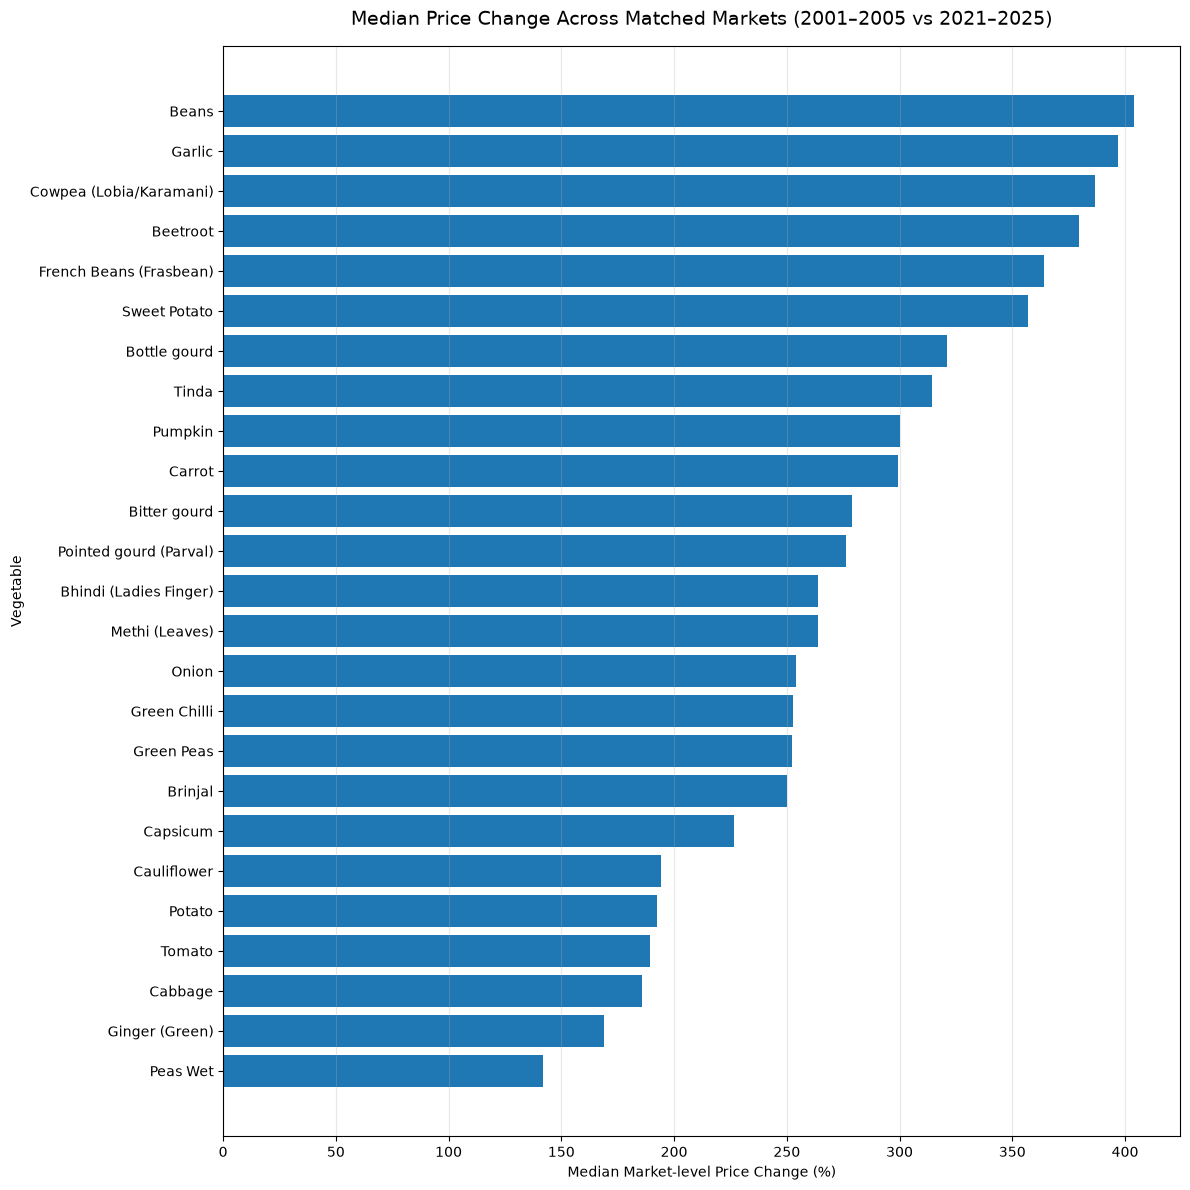

In [20]:
# 3.8 Visualise matched-market price changes

matched_plot = matched_market_prices[
    matched_market_prices["Matched_Markets"] >= 20
].sort_values("Median_Market_Price_Change_Percent")

plt.figure(figsize=(12, 12))

plt.barh(
    matched_plot["Project_Commodity"],
    matched_plot["Median_Market_Price_Change_Percent"]
)

plt.title(
    "Median Price Change Across Matched Markets (2001–2005 vs 2021–2025)",
    fontsize=14,
    pad=15
)

plt.xlabel("Median Market-level Price Change (%)")
plt.ylabel("Vegetable")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

---

# 4. Seasonal Price Patterns

Agricultural commodity prices can exhibit recurring seasonal patterns due to changes in production cycles, harvesting periods, weather conditions, and market availability.

This section examines whether particular vegetables consistently experience higher or lower wholesale modal prices during specific months.

The analysis uses monthly median prices from January 2015 to October 2025.

### Questions to investigate

- Which months tend to have relatively high or low prices for each vegetable?
- Are seasonal patterns consistent across different years?
- Which vegetables show the strongest seasonal price variation?
- How useful are these patterns for agricultural market intelligence?

In [21]:
# 4.1 Calculate monthly seasonal price indices

seasonal_prices = eda_con.execute("""
    SELECT
        Project_Commodity,
        EXTRACT(MONTH FROM Parsed_Date) AS Month_Number,
        MEDIAN(Modal_Price) AS Monthly_Median_Price,
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT EXTRACT(YEAR FROM Parsed_Date))
            AS Years_Represented

    FROM vegetable_prices

    WHERE Parsed_Date >= DATE '2015-01-01'
      AND Parsed_Date < DATE '2025-11-01'

    GROUP BY
        Project_Commodity,
        EXTRACT(MONTH FROM Parsed_Date)

    ORDER BY
        Project_Commodity,
        Month_Number
""").df()

seasonal_prices["Seasonal_Index"] = (
    seasonal_prices["Monthly_Median_Price"]
    / seasonal_prices.groupby("Project_Commodity")[
        "Monthly_Median_Price"
    ].transform("mean")
    * 100
).round(2)

print("Seasonal dataset shape:", seasonal_prices.shape)
print(
    "Vegetables represented:",
    seasonal_prices["Project_Commodity"].nunique()
)

display(seasonal_prices.head(15))

Seasonal dataset shape: (540, 6)
Vegetables represented: 45


,Project_Commodity,Month_Number,Monthly_Median_Price,Total_Records,Years_Represented,Seasonal_Index
0,Amaranthus,1,2600.0,17140,11,102.21
1,Amaranthus,2,2500.0,16411,11,98.28
2,Amaranthus,3,2500.0,17397,11,98.28
3,Amaranthus,4,2500.0,16203,11,98.28
4,Amaranthus,5,2500.0,17486,11,98.28
5,Amaranthus,6,2500.0,17591,11,98.28
6,Amaranthus,7,2500.0,20261,11,98.28
7,Amaranthus,8,2524.0,20628,11,99.23
8,Amaranthus,9,2500.0,20665,11,98.28
9,Amaranthus,10,2600.0,20216,11,102.21


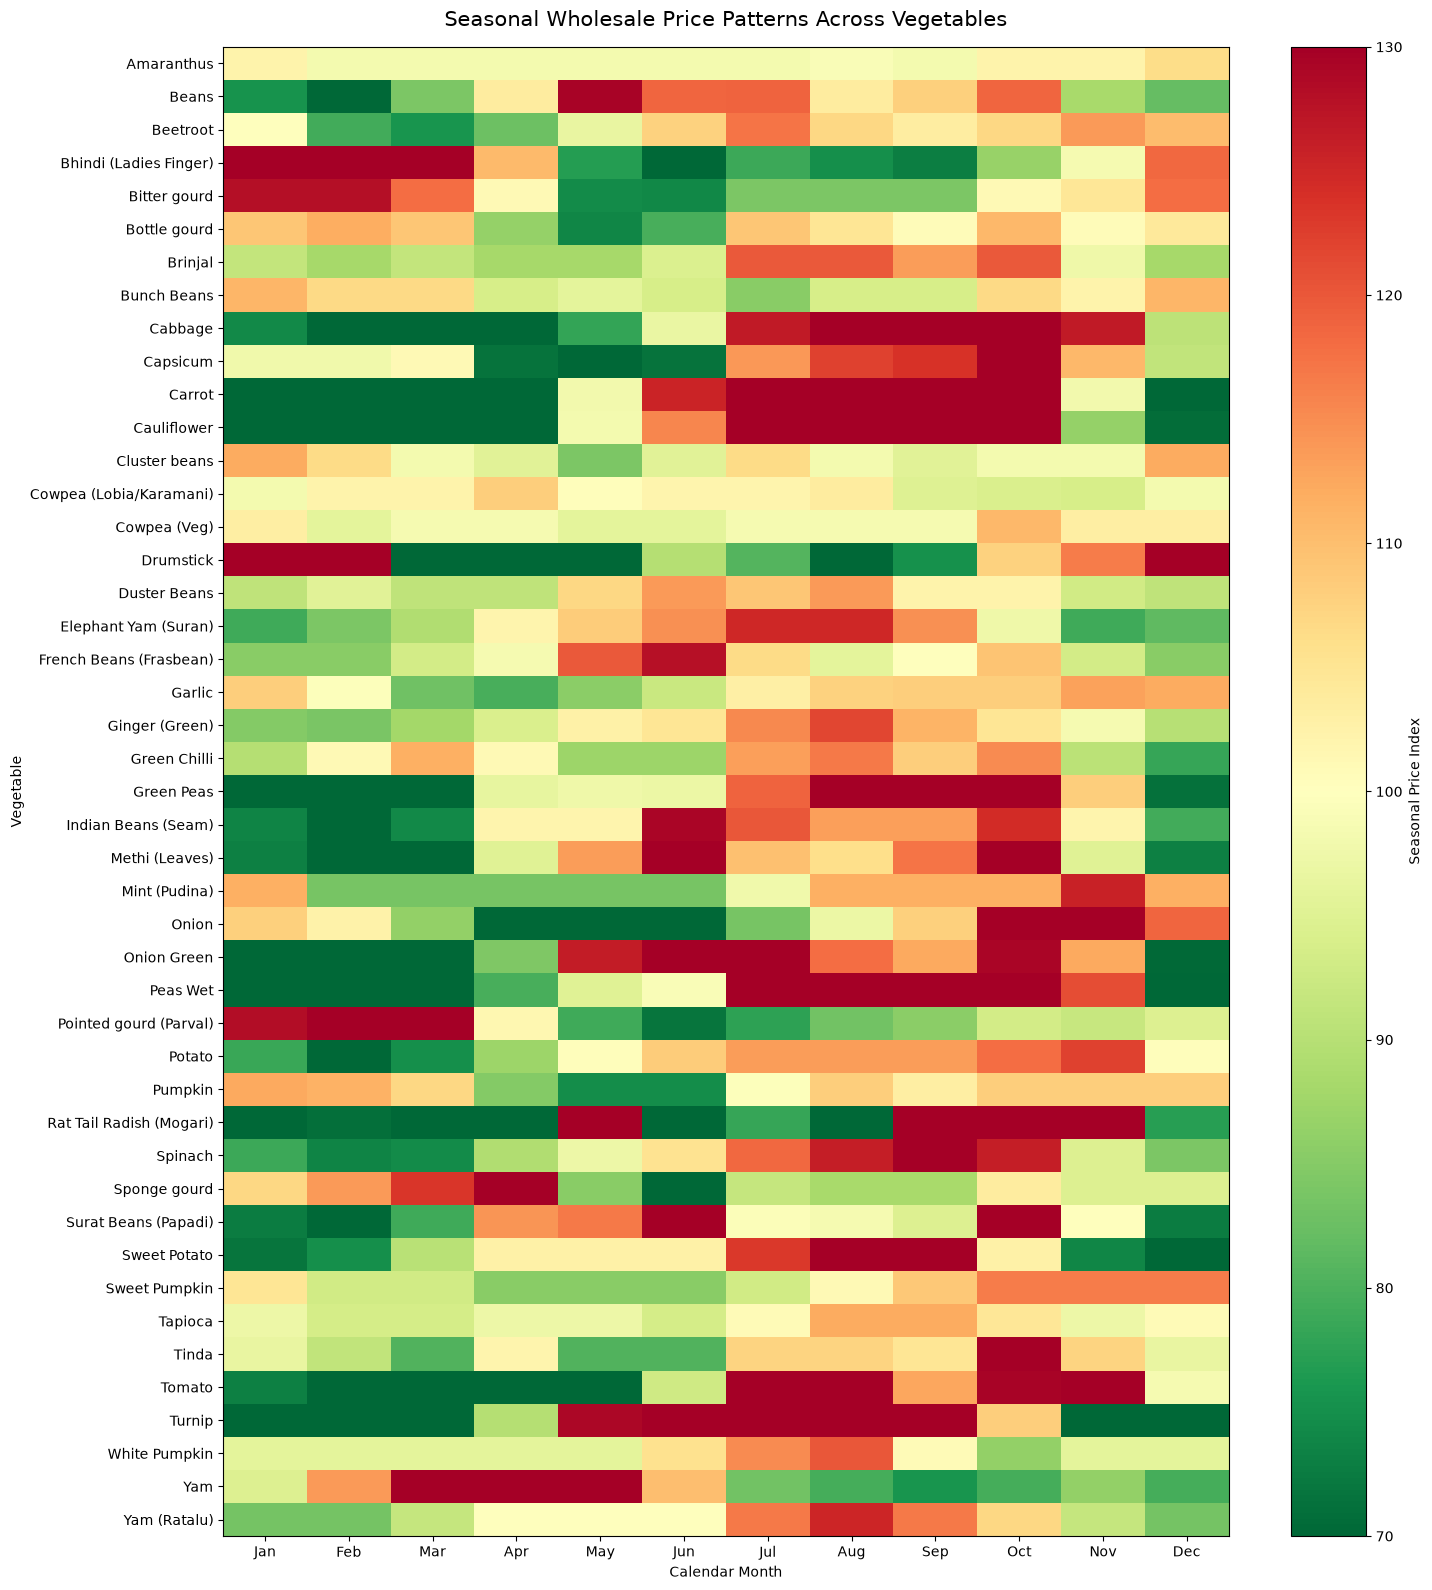

In [22]:
# 4.2 Visualise seasonal price indices using a heatmap

seasonal_pivot = seasonal_prices.pivot(
    index="Project_Commodity",
    columns="Month_Number",
    values="Seasonal_Index"
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

seasonal_pivot.columns = month_labels

plt.figure(figsize=(15, 16))

image = plt.imshow(
    seasonal_pivot,
    aspect="auto",
    cmap="RdYlGn_r",
    vmin=70,
    vmax=130
)

plt.colorbar(
    image,
    label="Seasonal Price Index"
)

plt.xticks(
    range(12),
    month_labels
)

plt.yticks(
    range(len(seasonal_pivot.index)),
    seasonal_pivot.index
)

plt.title(
    "Seasonal Wholesale Price Patterns Across Vegetables",
    fontsize=15,
    pad=15
)

plt.xlabel("Calendar Month")
plt.ylabel("Vegetable")

plt.tight_layout()
plt.show()

In [23]:
# 4.3 Identify recurring seasonal highs and lows

seasonal_consistency = eda_con.execute("""
    WITH yearly_monthly_prices AS (
        SELECT
            Project_Commodity,
            EXTRACT(YEAR FROM Parsed_Date) AS Year,
            EXTRACT(MONTH FROM Parsed_Date) AS Month_Number,
            MEDIAN(Modal_Price) AS Monthly_Median_Price

        FROM vegetable_prices

        WHERE Parsed_Date >= DATE '2015-01-01'
          AND Parsed_Date < DATE '2025-11-01'

        GROUP BY
            Project_Commodity,
            EXTRACT(YEAR FROM Parsed_Date),
            EXTRACT(MONTH FROM Parsed_Date)
    ),

    yearly_baselines AS (
        SELECT
            Project_Commodity,
            Year,
            MEDIAN(Monthly_Median_Price) AS Yearly_Median_Price

        FROM yearly_monthly_prices
        GROUP BY Project_Commodity, Year
    ),

    comparisons AS (
        SELECT
            m.Project_Commodity,
            m.Month_Number,
            m.Year,
            m.Monthly_Median_Price,
            b.Yearly_Median_Price,

            m.Monthly_Median_Price
                / b.Yearly_Median_Price * 100 AS Yearly_Index

        FROM yearly_monthly_prices m

        JOIN yearly_baselines b
          ON m.Project_Commodity = b.Project_Commodity
         AND m.Year = b.Year
    )

    SELECT
        Project_Commodity,
        Month_Number,
        COUNT(*) AS Years_Represented,

        MEDIAN(Yearly_Index) AS Median_Yearly_Index,

        AVG(
            CASE WHEN Yearly_Index >= 110
                 THEN 1.0 ELSE 0.0 END
        ) * 100 AS Years_Above_110,

        AVG(
            CASE WHEN Yearly_Index <= 90
                 THEN 1.0 ELSE 0.0 END
        ) * 100 AS Years_Below_90

    FROM comparisons
    GROUP BY Project_Commodity, Month_Number
    HAVING COUNT(*) >= 8

    ORDER BY Project_Commodity, Month_Number
""").df()

seasonal_consistency[
    ["Median_Yearly_Index", "Years_Above_110", "Years_Below_90"]
] = seasonal_consistency[
    ["Median_Yearly_Index", "Years_Above_110", "Years_Below_90"]
].round(2)

# Strong recurring high-price months
seasonal_highs = seasonal_consistency[
    (seasonal_consistency["Median_Yearly_Index"] >= 110)
    & (seasonal_consistency["Years_Above_110"] >= 70)
].sort_values(
    ["Median_Yearly_Index", "Years_Above_110"],
    ascending=False
)

# Strong recurring low-price months
seasonal_lows = seasonal_consistency[
    (seasonal_consistency["Median_Yearly_Index"] <= 90)
    & (seasonal_consistency["Years_Below_90"] >= 70)
].sort_values(
    ["Median_Yearly_Index", "Years_Below_90"]
)

print("Recurring high-price seasonal patterns:")
display(seasonal_highs.head(20))

print("Recurring low-price seasonal patterns:")
display(seasonal_lows.head(20))

Recurring high-price seasonal patterns:


,Project_Commodity,Month_Number,Years_Represented,Median_Yearly_Index,Years_Above_110,Years_Below_90
180,Drumstick,1,11,233.77,100.00,0.00
387,Rat Tail Radish (Mogari),11,8,221.24,100.00,0.00
191,Drumstick,12,10,217.46,90.00,0.00
345,Peas Wet,10,11,191.18,100.00,0.00
349,Pointed gourd (Parval),2,11,186.67,100.00,0.00
344,Peas Wet,9,11,171.43,100.00,0.00
479,Tomato,7,11,170.40,100.00,0.00
297,Methi (Leaves),10,11,166.67,100.00,0.00
181,Drumstick,2,11,166.29,90.91,9.09
422,Surat Beans (Papadi),10,11,166.28,100.00,0.00


Recurring low-price seasonal patterns:


,Project_Commodity,Month_Number,Years_Represented,Median_Yearly_Index,Years_Above_110,Years_Below_90
265,Green Peas,2,11,40.40,0.0,100.00
121,Carrot,2,11,41.00,0.0,100.00
337,Peas Wet,2,11,42.86,0.0,100.00
338,Peas Wet,3,11,43.04,0.0,100.00
264,Green Peas,1,11,43.24,0.0,90.91
266,Green Peas,3,11,45.51,0.0,100.00
120,Carrot,1,11,46.67,0.0,100.00
122,Carrot,3,11,46.67,0.0,100.00
336,Peas Wet,1,11,48.57,0.0,100.00
112,Capsicum,5,11,52.08,0.0,100.00


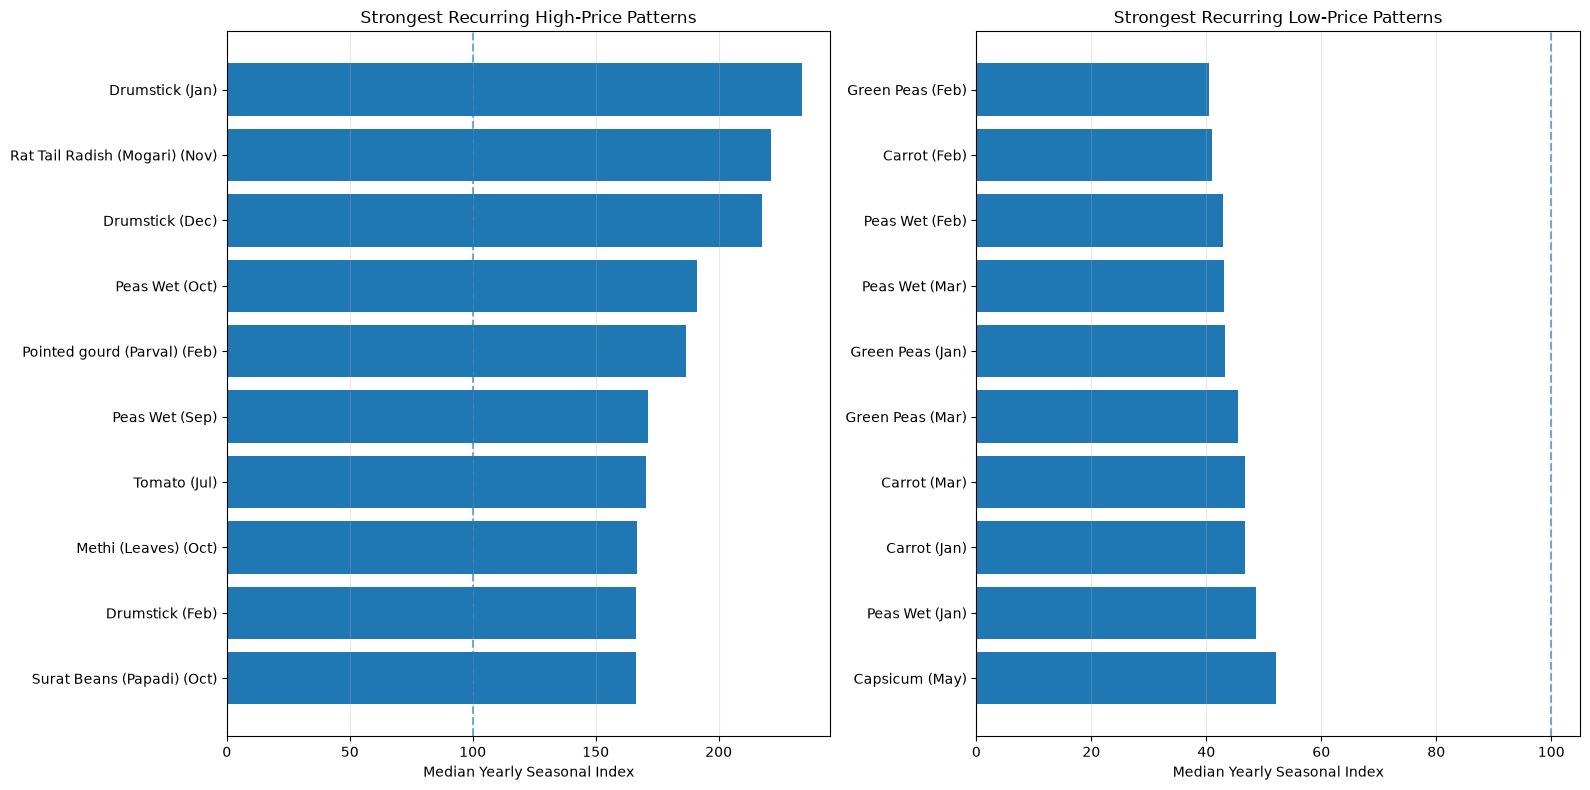

In [24]:
# 4.4 Visualise strongest recurring seasonal patterns

month_names = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr",
    5: "May", 6: "Jun", 7: "Jul", 8: "Aug",
    9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}

high_plot = seasonal_highs.head(10).copy()
low_plot = seasonal_lows.head(10).copy()

high_plot["Month"] = high_plot["Month_Number"].map(month_names)
low_plot["Month"] = low_plot["Month_Number"].map(month_names)

high_plot["Label"] = (
    high_plot["Project_Commodity"] + " (" + high_plot["Month"] + ")"
)

low_plot["Label"] = (
    low_plot["Project_Commodity"] + " (" + low_plot["Month"] + ")"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

high_plot = high_plot.sort_values("Median_Yearly_Index")
low_plot = low_plot.sort_values("Median_Yearly_Index", ascending=False)

axes[0].barh(
    high_plot["Label"],
    high_plot["Median_Yearly_Index"]
)
axes[0].set_title("Strongest Recurring High-Price Patterns")
axes[0].set_xlabel("Median Yearly Seasonal Index")

axes[1].barh(
    low_plot["Label"],
    low_plot["Median_Yearly_Index"]
)
axes[1].set_title("Strongest Recurring Low-Price Patterns")
axes[1].set_xlabel("Median Yearly Seasonal Index")

for ax in axes:
    ax.axvline(100, linestyle="--", alpha=0.6)
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

---

# 5. Price Volatility

Price volatility measures the extent to which wholesale prices fluctuate over time.

This section examines monthly price changes across the selected vegetables to identify commodities with relatively stable prices and those experiencing larger fluctuations.

Monthly median prices are used to reduce the influence of individual extreme observations.

### Questions to investigate

- Which vegetables experience the greatest monthly price fluctuations?
- Which vegetables have relatively stable prices?
- How frequently do substantial monthly price increases or decreases occur?
- Are volatility patterns consistent across different vegetables?

In [25]:
# 5.1 Calculate monthly price changes and volatility

volatility_data = monthly_prices.sort_values(
    ["Project_Commodity", "Month"]
).copy()

volatility_data["Monthly_Change_Percent"] = (
    volatility_data.groupby("Project_Commodity")[
        "Median_Modal_Price"
    ].pct_change() * 100
)

volatility_summary = (
    volatility_data
    .groupby("Project_Commodity")
    .agg(
        Monthly_Observations=("Median_Modal_Price", "count"),
        Median_Absolute_Change=(
            "Monthly_Change_Percent",
            lambda x: x.abs().median()
        ),
        P90_Absolute_Change=(
            "Monthly_Change_Percent",
            lambda x: x.abs().quantile(0.90)
        ),
        Maximum_Absolute_Change=(
            "Monthly_Change_Percent",
            lambda x: x.abs().max()
        )
    )
    .reset_index()
)

volatility_summary[
    [
        "Median_Absolute_Change",
        "P90_Absolute_Change",
        "Maximum_Absolute_Change"
    ]
] = volatility_summary[
    [
        "Median_Absolute_Change",
        "P90_Absolute_Change",
        "Maximum_Absolute_Change"
    ]
].round(2)

volatility_summary = volatility_summary.sort_values(
    "Median_Absolute_Change",
    ascending=False
)

display(volatility_summary)

,Project_Commodity,Monthly_Observations,Median_Absolute_Change,P90_Absolute_Change,Maximum_Absolute_Change
33,Rat Tail Radish (Mogari),177,35.71,188.05,1337.50
36,Surat Beans (Papadi),281,28.08,71.73,3025.00
25,Methi (Leaves),294,24.16,53.72,192.31
15,Drumstick,294,23.62,61.88,200.00
10,Carrot,294,20.00,50.00,150.00
29,Peas Wet,293,20.00,56.66,180.00
11,Cauliflower,304,19.21,48.70,200.00
41,Tomato,303,16.90,58.13,346.15
28,Onion Green,263,16.67,41.67,7042.86
42,Turnip,254,16.67,62.22,323.08


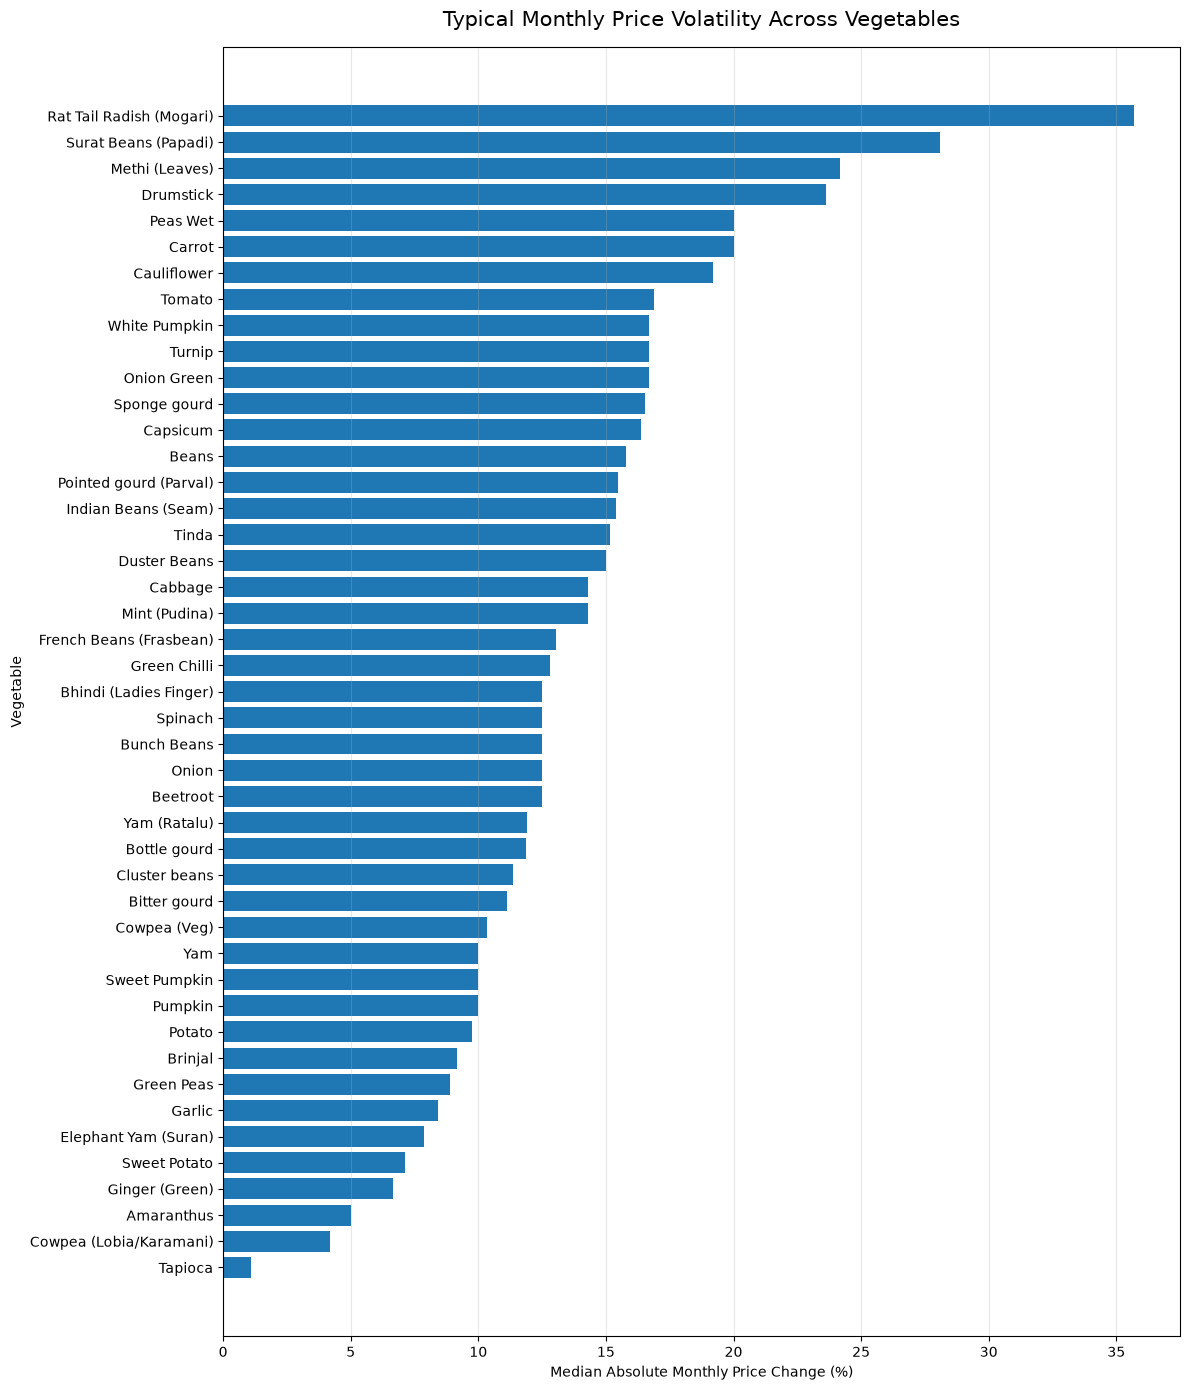

In [26]:
# 5.2 Visualise median absolute monthly price changes

volatility_plot = volatility_summary[
    volatility_summary["Monthly_Observations"] >= 100
].sort_values("Median_Absolute_Change")

plt.figure(figsize=(12, 14))

plt.barh(
    volatility_plot["Project_Commodity"],
    volatility_plot["Median_Absolute_Change"]
)

plt.title(
    "Typical Monthly Price Volatility Across Vegetables",
    fontsize=15,
    pad=15
)

plt.xlabel("Median Absolute Monthly Price Change (%)")
plt.ylabel("Vegetable")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# 5.3 Identify extreme monthly price movements

extreme_movements = volatility_data[
    volatility_data["Monthly_Change_Percent"].abs() >= 100
].copy()

extreme_movements["Previous_Month_Price"] = (
    extreme_movements.groupby("Project_Commodity")[
        "Median_Modal_Price"
    ].shift(1)
)

extreme_movements = extreme_movements[
    [
        "Project_Commodity",
        "Month",
        "Previous_Month_Price",
        "Median_Modal_Price",
        "Monthly_Change_Percent",
        "Total_Records",
        "Active_Markets"
    ]
].sort_values(
    "Monthly_Change_Percent",
    key=lambda x: x.abs(),
    ascending=False
)

print("Extreme monthly movements:", len(extreme_movements))

display(extreme_movements.head(25))

Extreme monthly movements: 185


,Project_Commodity,Month,Previous_Month_Price,Median_Modal_Price,Monthly_Change_Percent,Total_Records,Active_Markets
7580,Mint (Pudina),2024-07-01,1825.0,4000.0,7172.727273,4041,252
8147,Onion Green,2024-07-01,2450.0,5000.0,7042.857143,4258,264
12849,Yam (Ratalu),2024-07-01,2400.0,8000.0,5614.285714,1792,129
8463,Pointed gourd (Parval),2002-09-01,NaN,10500.0,5150.000000,3,1
12590,Yam (Ratalu),2002-09-01,NaN,52500.0,5150.000000,1,1
4997,Elephant Yam (Suran),2002-09-01,NaN,4500.0,4900.000000,3,1
559,Beans,2024-07-01,1000.0,7000.0,4017.647059,4265,279
6760,Indian Beans (Seam),2002-09-01,NaN,7000.0,3788.888889,3,1
10066,Surat Beans (Papadi),2002-09-01,NaN,18750.0,3025.000000,3,1
6792,Indian Beans (Seam),2005-06-01,17500.0,20000.0,2757.142857,11,2


In [28]:
# 5.4 Classify extreme movements by reporting coverage

extreme_movements["Coverage_Category"] = np.select(
    [
        (extreme_movements["Total_Records"] < 10)
        | (extreme_movements["Active_Markets"] < 3),

        (extreme_movements["Total_Records"] < 100)
        | (extreme_movements["Active_Markets"] < 10)
    ],
    [
        "Very Low Coverage",
        "Low Coverage"
    ],
    default="Higher Coverage"
)

coverage_summary = (
    extreme_movements
    .groupby("Coverage_Category")
    .agg(
        Extreme_Movements=("Project_Commodity", "count"),
        Median_Absolute_Change=(
            "Monthly_Change_Percent",
            lambda x: x.abs().median()
        ),
        Median_Records=("Total_Records", "median"),
        Median_Active_Markets=("Active_Markets", "median")
    )
    .reset_index()
)

display(coverage_summary)

,Coverage_Category,Extreme_Movements,Median_Absolute_Change,Median_Records,Median_Active_Markets
0,Higher Coverage,64,133.333333,1305.0,102.5
1,Low Coverage,46,132.941176,44.5,7.0
2,Very Low Coverage,75,193.750000,4.0,1.0


### 5.5 Price Volatility: Key Findings

Monthly price volatility varies considerably across the 46 selected vegetables.

- Rat Tail Radish, Surat Beans, Methi, and Drumstick show relatively high typical monthly price fluctuations.
- Tapioca, Cowpea Lobia, Amaranthus, and Ginger show lower typical fluctuations.
- A total of 185 monthly movements exceeded an absolute change of 100%.
- Of these, 75 occurred with fewer than 10 records or fewer than 3 reporting markets.
- Extreme movements also occurred under higher reporting coverage, indicating that sparse reporting alone does not explain all unusual price behaviour.

**Analytical implication:** Volatility indicators should be interpreted alongside observation counts and market coverage. Large percentage changes should not automatically be treated as reliable market-wide price signals.

The analysis is based on changes between consecutive available monthly observations, which may span more than one calendar month when reporting is missing.

---

# 6. Geographical Price Variation

Wholesale prices can differ across geographical regions due to differences in production, transportation, local demand, market access, and other factors.

This section examines how median wholesale prices vary across states for the selected vegetables.

The analysis uses observations from January 2021 to October 2025 to reduce the influence of the severe reporting decline after October 2025.

### Questions to investigate

- How do wholesale prices differ across states?
- Which vegetables show substantial geographical price variation?
- Are geographical differences consistent across reporting markets?
- How should differences in market coverage affect interpretation?

In [29]:
# 6.1 Calculate state-level wholesale price statistics

state_prices = eda_con.execute("""
    SELECT
        Project_Commodity,
        State,

        MEDIAN(Modal_Price) AS Median_Modal_Price,
        COUNT(*) AS Total_Records,

        COUNT(DISTINCT (District, Market))
            AS Market_Identities,

        COUNT(DISTINCT Parsed_Date)
            AS Reporting_Days

    FROM vegetable_prices

    WHERE Parsed_Date >= DATE '2021-01-01'
      AND Parsed_Date < DATE '2025-11-01'

    GROUP BY
        Project_Commodity,
        State

    HAVING COUNT(*) >= 100
       AND COUNT(DISTINCT (District, Market)) >= 3

    ORDER BY
        Project_Commodity,
        Median_Modal_Price DESC
""").df()

print("State-level observations:", len(state_prices))
print(
    "Vegetables represented:",
    state_prices["Project_Commodity"].nunique()
)
print(
    "States represented:",
    state_prices["State"].nunique()
)

display(state_prices.head(20))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

State-level observations: 587
Vegetables represented: 45
States represented: 26


,Project_Commodity,State,Median_Modal_Price,Total_Records,Market_Identities,Reporting_Days
0,Amaranthus,Andaman and Nicobar,4000.0,140,4,136
1,Amaranthus,Kerala,3000.0,69795,126,1765
2,Amaranthus,Tamil Nadu,2500.0,72855,244,481
3,Amaranthus,Chattisgarh,2000.0,221,4,119
4,Amaranthus,Madhya Pradesh,1400.0,419,5,403
5,Amaranthus,Tripura,750.0,530,4,487
6,Beans,Tamil Nadu,7000.0,59503,223,481
7,Beans,Gujarat,6250.0,2416,15,1285
8,Beans,Nagaland,6000.0,2825,8,1457
9,Beans,Kerala,5100.0,3340,8,1544


In [30]:
# 6.2 Measure geographical price variation by vegetable

geographical_variation = (
    state_prices
    .groupby("Project_Commodity")
    .agg(
        States_Represented=("State", "nunique"),
        Lowest_State_Median=("Median_Modal_Price", "min"),
        Highest_State_Median=("Median_Modal_Price", "max"),
        Median_State_Price=("Median_Modal_Price", "median"),
        State_Price_IQR=(
            "Median_Modal_Price",
            lambda x: x.quantile(0.75) - x.quantile(0.25)
        )
    )
    .reset_index()
)

geographical_variation["Geographical_Spread_Percent"] = (
    (
        geographical_variation["Highest_State_Median"]
        - geographical_variation["Lowest_State_Median"]
    )
    / geographical_variation["Lowest_State_Median"]
    * 100
).round(2)

geographical_variation["State_Price_IQR"] = (
    geographical_variation["State_Price_IQR"].round(2)
)

geographical_variation = geographical_variation[
    geographical_variation["States_Represented"] >= 5
].sort_values(
    "Geographical_Spread_Percent",
    ascending=False
)

display(geographical_variation)

,Project_Commodity,States_Represented,Lowest_State_Median,Highest_State_Median,Median_State_Price,State_Price_IQR,Geographical_Spread_Percent
25,Mint (Pudina),7,4.0,6500.0,3000.0,1550.00,162400.00
21,Green Chilli,23,2000.0,25000.0,3500.0,2250.00,1150.00
27,Onion Green,9,450.0,5400.0,1750.0,1200.00,1100.00
6,Brinjal,24,950.0,10000.0,1900.0,1575.00,952.63
2,Beetroot,17,1000.0,8000.0,2100.0,2200.00,700.00
10,Carrot,22,1000.0,8000.0,2025.0,2475.00,700.00
4,Bitter gourd,24,1400.0,10000.0,2875.0,1775.00,614.29
22,Green Peas,12,1800.0,12500.0,3950.0,4500.00,594.44
31,Pumpkin,22,800.0,5500.0,1375.0,950.00,587.50
5,Bottle gourd,24,900.0,6000.0,1375.0,799.96,566.67


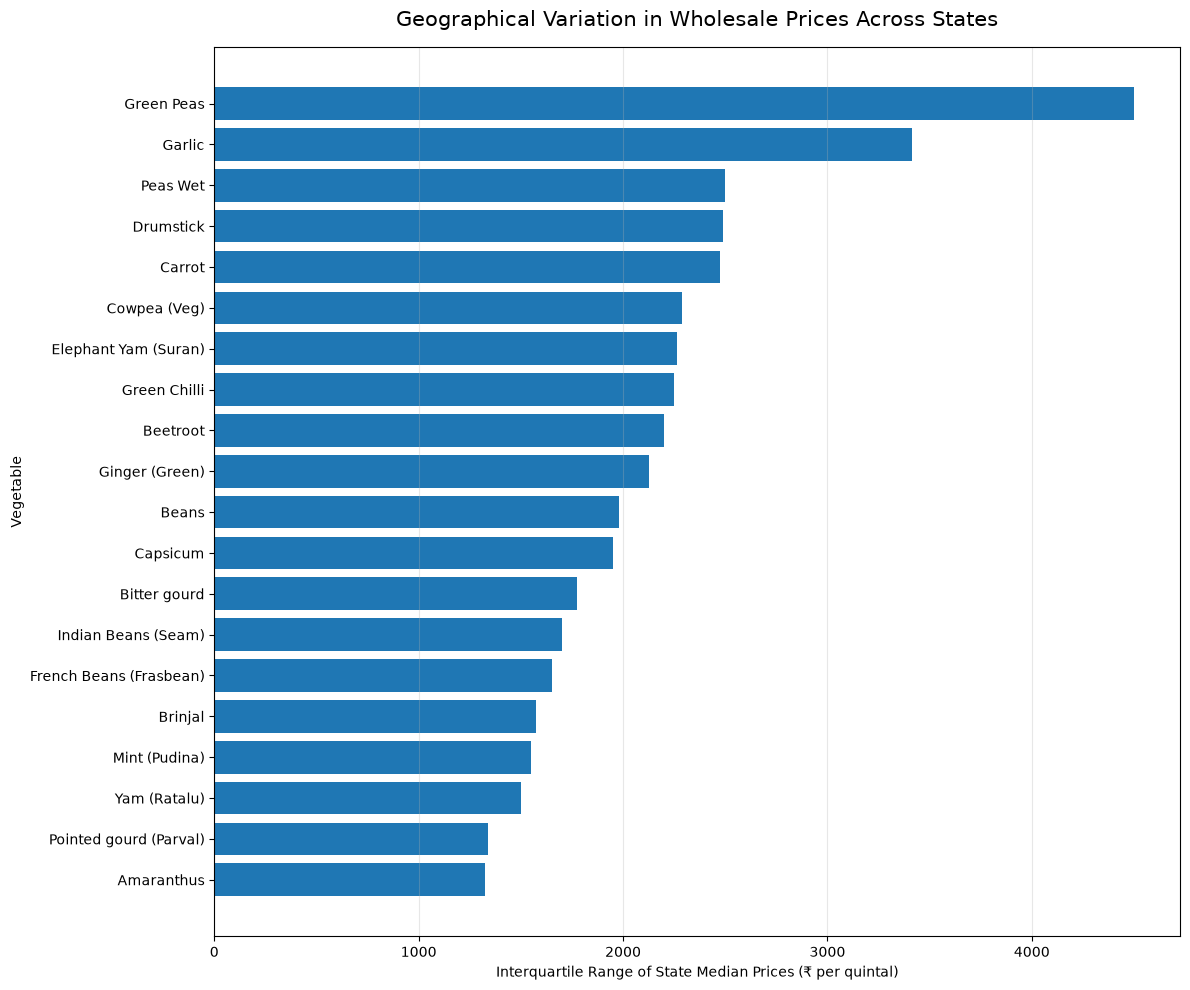

In [31]:
# 6.3 Visualise geographical price variation using IQR

geographical_plot = geographical_variation.sort_values(
    "State_Price_IQR"
).tail(20)

plt.figure(figsize=(12, 10))

plt.barh(
    geographical_plot["Project_Commodity"],
    geographical_plot["State_Price_IQR"]
)

plt.title(
    "Geographical Variation in Wholesale Prices Across States",
    fontsize=15,
    pad=15
)

plt.xlabel("Interquartile Range of State Median Prices (₹ per quintal)")
plt.ylabel("Vegetable")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
# 6.4 Compare highest- and lowest-price states for selected vegetables

selected_commodities = [
    "Green Chilli",
    "Brinjal",
    "Beetroot",
    "Carrot",
    "Potato",
    "Onion",
    "Tomato"
]

state_comparison = state_prices[
    state_prices["Project_Commodity"].isin(selected_commodities)
].copy()

state_comparison["Price_Rank"] = (
    state_comparison
    .groupby("Project_Commodity")["Median_Modal_Price"]
    .rank(method="min", ascending=False)
    .astype(int)
)

state_comparison = state_comparison[
    (state_comparison["Price_Rank"] <= 3)
    | (
        state_comparison.groupby("Project_Commodity")["Price_Rank"]
        .transform("max") - state_comparison["Price_Rank"] < 3
    )
].sort_values(
    ["Project_Commodity", "Price_Rank"]
)

display(
    state_comparison[
        [
            "Project_Commodity",
            "State",
            "Median_Modal_Price",
            "Price_Rank",
            "Total_Records",
            "Market_Identities",
            "Reporting_Days"
        ]
    ]
)

,Project_Commodity,State,Median_Modal_Price,Price_Rank,Total_Records,Market_Identities,Reporting_Days
18,Beetroot,Meghalaya,8000.0,1,514,6,453
19,Beetroot,Tamil Nadu,4000.0,2,60573,222,482
20,Beetroot,Odisha,4000.0,2,618,6,521
32,Beetroot,Uttar Pradesh,1400.0,15,1137,11,892
33,Beetroot,Rajasthan,1400.0,15,2337,6,1230
34,Beetroot,Madhya Pradesh,1000.0,17,710,14,559
107,Brinjal,Andaman and Nicobar,10000.0,1,218,4,209
108,Brinjal,Tamil Nadu,4000.0,2,69953,252,491
109,Brinjal,Meghalaya,3800.0,3,1651,13,902
128,Brinjal,Haryana,1300.0,22,38906,71,1765


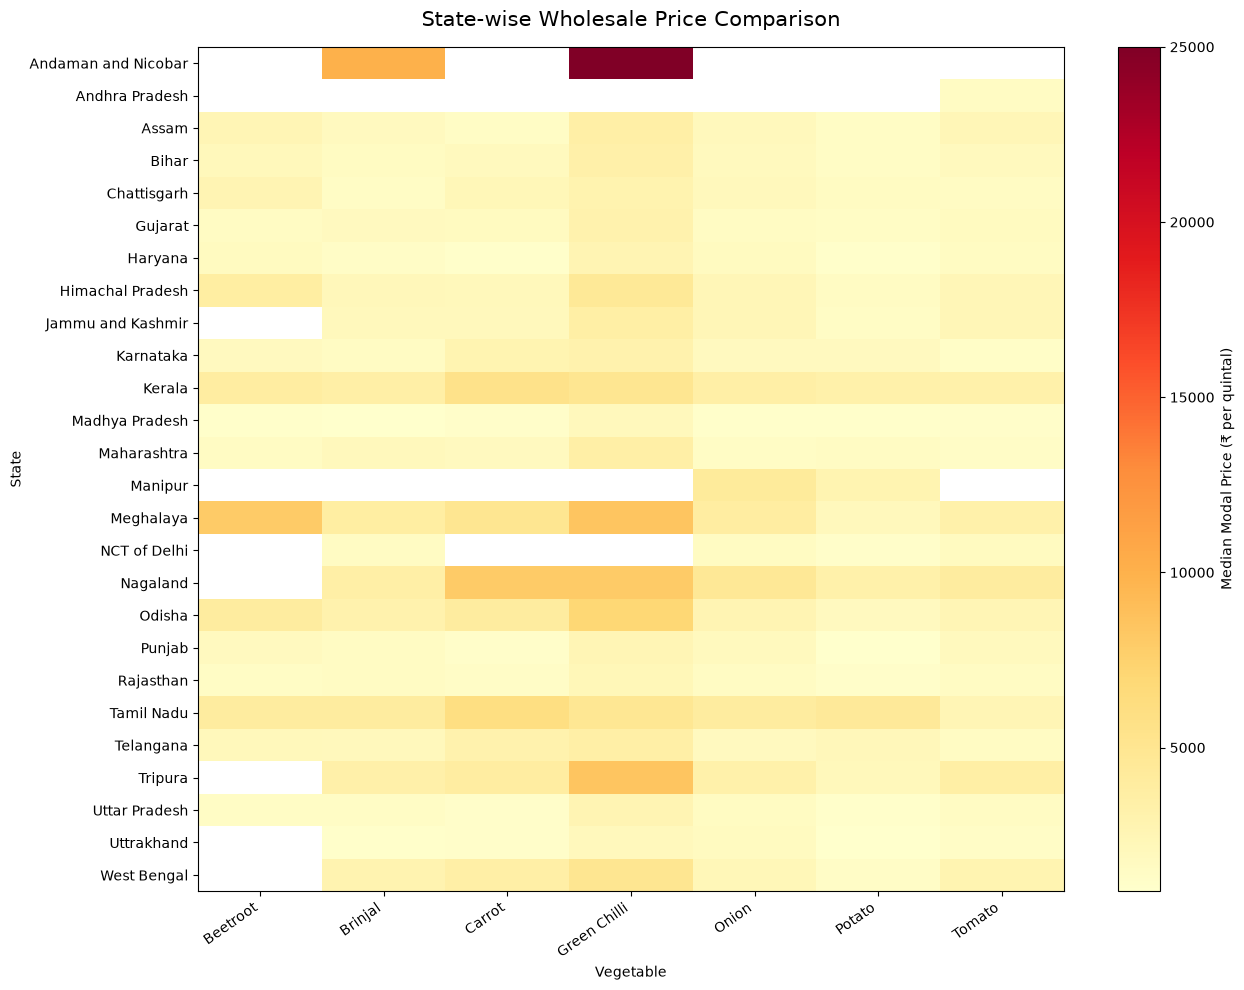

In [33]:
# 6.5 Visualise state-level price differences

state_heatmap = state_prices[
    state_prices["Project_Commodity"].isin(selected_commodities)
].pivot(
    index="State",
    columns="Project_Commodity",
    values="Median_Modal_Price"
)

plt.figure(figsize=(13, 10))

image = plt.imshow(
    state_heatmap,
    aspect="auto",
    cmap="YlOrRd"
)

plt.colorbar(
    image,
    label="Median Modal Price (₹ per quintal)"
)

plt.xticks(
    range(len(state_heatmap.columns)),
    state_heatmap.columns,
    rotation=35,
    ha="right"
)

plt.yticks(
    range(len(state_heatmap.index)),
    state_heatmap.index
)

plt.title(
    "State-wise Wholesale Price Comparison",
    fontsize=15,
    pad=15
)

plt.xlabel("Vegetable")
plt.ylabel("State")

plt.tight_layout()
plt.show()

In [34]:
# 6.6 Examine market coverage across selected vegetables

state_coverage = (
    state_prices[
        state_prices["Project_Commodity"].isin(selected_commodities)
    ]
    .groupby("Project_Commodity")
    .agg(
        States=("State", "nunique"),
        Total_Markets=("Market_Identities", "sum"),
        Minimum_Markets_Per_State=("Market_Identities", "min"),
        Median_Markets_Per_State=("Market_Identities", "median"),
        Maximum_Markets_Per_State=("Market_Identities", "max")
    )
    .reset_index()
)

display(state_coverage)

,Project_Commodity,States,Total_Markets,Minimum_Markets_Per_State,Median_Markets_Per_State,Maximum_Markets_Per_State
0,Beetroot,17,502,4,12.0,222
1,Brinjal,24,1505,3,44.0,252
2,Carrot,22,1033,5,27.5,223
3,Green Chilli,23,1394,4,46.0,250
4,Onion,24,1536,3,44.5,251
5,Potato,24,1457,3,40.0,228
6,Tomato,24,1574,3,50.0,254


### 6.7 Geographical Variation: Key Findings

The analysis identifies substantial differences in wholesale modal prices across Indian states.

- Green Chilli, Brinjal, Beetroot, and Carrot show considerable geographical price variation.
- Tamil Nadu frequently appears among the higher-price states for the selected vegetables.
- Madhya Pradesh appears among the lower-price states for several selected vegetables.
- Major vegetables such as Tomato, Onion, Potato, and Brinjal have relatively broad geographical coverage.
- Reporting coverage varies considerably between states, making some state-level estimates less reliable than others.

**Analytical implication:** Geographical price differences can help identify potential markets for further investigation. However, higher wholesale prices do not automatically imply better selling opportunities.

The comparisons use pooled state-level medians from 2021–October 2025. Differences in reporting dates, market composition, varieties, grades, and local conditions may influence the results.

These findings should not be interpreted as direct recommendations for transporting produce between states.

---

# 7. Data Anomalies and Investigation

Historical agricultural price datasets can contain unusual observations arising from reporting errors, inconsistent units, market-specific conditions, or genuine price movements.

This section investigates selected unusual observations to understand their context and assess whether they should be flagged for further validation.

### Questions to investigate

- Are unusually high or low prices concentrated in particular markets?
- Do suspicious observations coincide with changes in reporting coverage?
- Are unusual prices isolated or repeated over time?
- Which observations require further validation before being used in market intelligence or forecasting?

In [35]:
# 7.1 Investigate Drumstick prices reported by Pothencode

pothencode_drumstick = eda_con.execute("""
    SELECT
        Parsed_Date,
        State,
        District,
        Market,
        Variety,
        Grade,
        Min_Price,
        Max_Price,
        Modal_Price

    FROM vegetable_prices

    WHERE LOWER(Market) LIKE '%pothencode%'
      AND Project_Commodity = 'Drumstick'

    ORDER BY Parsed_Date
""").df()

print("Pothencode Drumstick observations:", len(pothencode_drumstick))

display(pothencode_drumstick)

Pothencode Drumstick observations: 1322


,Parsed_Date,State,District,Market,Variety,Grade,Min_Price,Max_Price,Modal_Price
0,2006-07-12,Kerala,Thiruvananthapuram,Pothencode,Other,FAQ,1900.0,2100.0,2000.0
1,2006-07-29,Kerala,Thiruvananthapuram,Pothencode,Other,FAQ,4000.0,4000.0,4000.0
2,2006-07-31,Kerala,Thiruvananthapuram,Pothencode,Other,FAQ,2000.0,2000.0,2000.0
3,2006-08-07,Kerala,Thiruvananthapuram,Pothencode,Other,FAQ,1600.0,1600.0,1600.0
4,2006-08-21,Kerala,Thiruvananthapuram,Pothencode,Other,FAQ,2000.0,2000.0,2000.0
...,...,...,...,...,...,...,...,...,...
1317,2026-04-08,Kerala,Thiruvananthapuram,Pothencode APMC,Drumstick,Local,4000.0,4200.0,4000.0
1318,2026-04-12,Kerala,Thiruvananthapuram,Pothencode APMC,Drumstick,Local,4000.0,4200.0,4000.0
1319,2026-04-17,Kerala,Thiruvananthapuram,Pothencode APMC,Drumstick,Local,4000.0,4200.0,4000.0
1320,2026-04-19,Kerala,Thiruvananthapuram,Pothencode APMC,Drumstick,Local,4000.0,4200.0,4000.0


In [36]:
# 7.2 Summarise Pothencode Drumstick price distribution

pothencode_summary = pothencode_drumstick[
    ["Min_Price", "Max_Price", "Modal_Price"]
].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(pothencode_summary)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Min_Price,1322.0,16540.355522,20561.077833,600.0,1821.0,2800.0,4000.0,7000.0,21000.0,66000.0,101580.0,120000.0
Max_Price,1322.0,16926.285930,20404.902709,600.0,2221.0,3005.0,4400.0,7580.0,21080.0,66080.0,101660.0,120080.0
Modal_Price,1322.0,16708.789713,20497.667633,600.0,2021.0,2952.5,4000.0,7500.0,21040.0,66040.0,101620.0,120040.0


In [37]:
# 7.3 Inspect the highest Pothencode Drumstick prices

pothencode_extremes = pothencode_drumstick.sort_values(
    "Modal_Price",
    ascending=False
)

display(
    pothencode_extremes[
        [
            "Parsed_Date",
            "Market",
            "Variety",
            "Grade",
            "Min_Price",
            "Max_Price",
            "Modal_Price"
        ]
    ].head(30)
)

,Parsed_Date,Market,Variety,Grade,Min_Price,Max_Price,Modal_Price
762,2023-12-30,Pothencode,Other,FAQ,120000.0,120080.0,120040.0
756,2023-12-23,Pothencode,Other,FAQ,120000.0,120080.0,120040.0
757,2023-12-25,Pothencode,Other,FAQ,120000.0,120070.0,120040.0
759,2023-12-27,Pothencode,Other,FAQ,114000.0,114080.0,114040.0
758,2023-12-26,Pothencode,Other,FAQ,110000.0,110080.0,110040.0
763,2024-01-01,Pothencode,Other,FAQ,110000.0,110080.0,110040.0
754,2023-12-21,Pothencode,Other,FAQ,110000.0,110080.0,110040.0
751,2023-12-16,Pothencode,Other,FAQ,108000.0,108080.0,108040.0
777,2024-01-17,Pothencode,Other,FAQ,108000.0,108080.0,108040.0
773,2024-01-13,Pothencode,Other,FAQ,105000.0,105080.0,105040.0


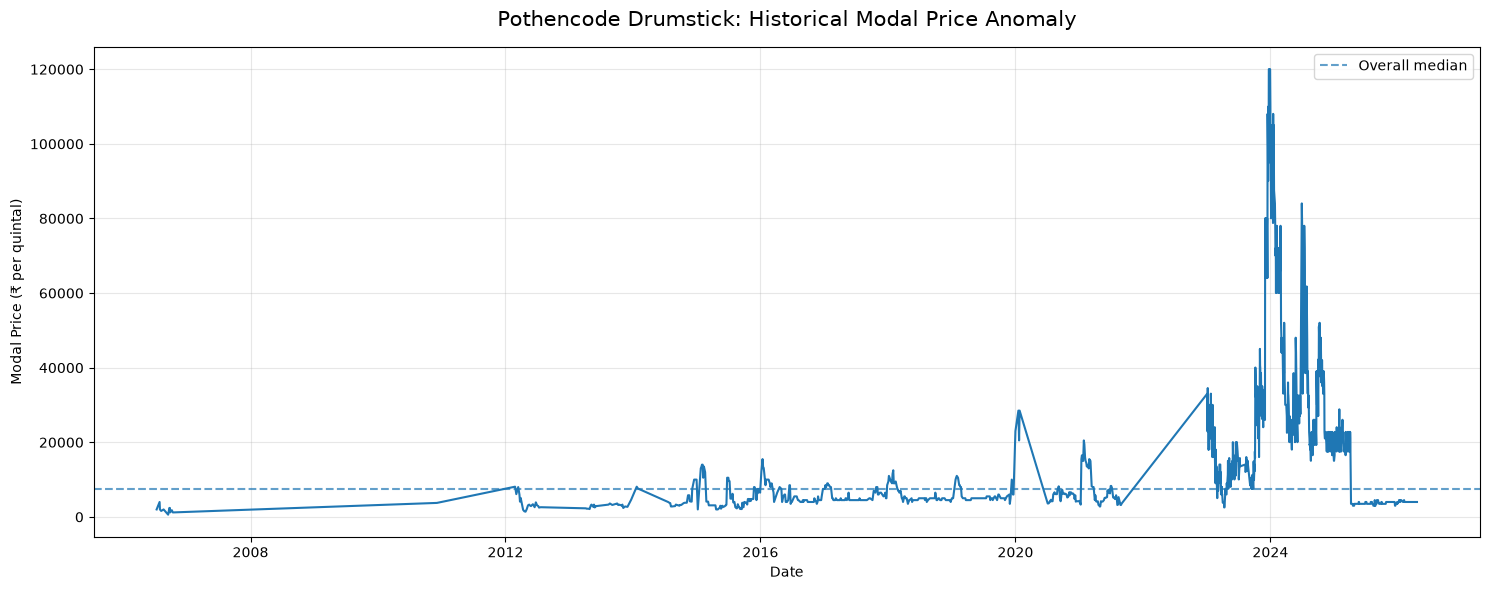

In [38]:
# Examine the Pothencode Drumstick price episode over time

pothencode_sorted = pothencode_drumstick.sort_values("Parsed_Date").copy()

plt.figure(figsize=(15, 6))

plt.plot(
    pothencode_sorted["Parsed_Date"],
    pothencode_sorted["Modal_Price"],
    linewidth=1.5
)

plt.axhline(
    pothencode_sorted["Modal_Price"].median(),
    linestyle="--",
    alpha=0.7,
    label="Overall median"
)

plt.title(
    "Pothencode Drumstick: Historical Modal Price Anomaly",
    fontsize=15,
    pad=15
)

plt.xlabel("Date")
plt.ylabel("Modal Price (₹ per quintal)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
# Identify the largest consecutive price movements in Pothencode

pothencode_changes = pothencode_sorted.copy()

pothencode_changes["Previous_Price"] = (
    pothencode_changes["Modal_Price"].shift(1)
)

pothencode_changes["Price_Change_Percent"] = (
    pothencode_changes["Modal_Price"].pct_change() * 100
)

display(
    pothencode_changes
    .assign(
        Absolute_Change=lambda x: x["Price_Change_Percent"].abs()
    )
    .sort_values("Absolute_Change", ascending=False)
    [[
        "Parsed_Date",
        "Previous_Price",
        "Modal_Price",
        "Price_Change_Percent"
    ]]
    .head(20)
)

,Parsed_Date,Previous_Price,Modal_Price,Price_Change_Percent
543,2023-01-04,3600.0,33020.0,817.222222
95,2015-01-24,2000.0,13000.0,550.000000
485,2021-01-13,3300.0,15500.0,369.696970
6,2006-09-23,600.0,2400.0,300.000000
429,2020-01-01,6000.0,23000.0,283.333333
125,2015-06-24,3300.0,10500.0,218.181818
11,2010-12-04,1200.0,3750.0,212.500000
742,2023-12-02,26040.0,80040.0,207.373272
890,2024-06-29,27540.0,84040.0,205.156137
697,2023-10-07,15780.0,40040.0,153.738910


In [40]:
# 7.5 Compare Drumstick prices across Kerala markets

kerala_drumstick = eda_con.execute("""
    SELECT
        Parsed_Date,
        Market,
        MEDIAN(Modal_Price) AS Median_Modal_Price,
        COUNT(*) AS Total_Records
    FROM vegetable_prices
    WHERE Project_Commodity = 'Drumstick'
      AND State = 'Kerala'
      AND Parsed_Date BETWEEN DATE '2023-10-01'
                          AND DATE '2024-03-31'
    GROUP BY Parsed_Date, Market
    ORDER BY Parsed_Date, Market
""").df()

display(
    kerala_drumstick[
        kerala_drumstick["Market"].str.contains(
            "Pothencode", case=False, na=False
        )
    ].head(20)
)

print("Kerala market observations:", len(kerala_drumstick))

,Parsed_Date,Market,Median_Modal_Price,Total_Records
30,2023-10-02,Pothencode,14040.0,1
74,2023-10-03,Pothencode,12280.0,1
124,2023-10-04,Pothencode,17540.0,1
174,2023-10-05,Pothencode,15780.0,1
269,2023-10-07,Pothencode,40040.0,1
321,2023-10-09,Pothencode,36040.0,1
363,2023-10-10,Pothencode,32040.0,1
409,2023-10-11,Pothencode,33780.0,1
455,2023-10-12,Pothencode,30040.0,1
534,2023-10-14,Pothencode,27040.0,1


Kerala market observations: 6659


In [41]:
# 7.6 Compare Pothencode prices with other Kerala markets

kerala_comparison = kerala_drumstick.copy()

kerala_comparison["Market_Group"] = np.where(
    kerala_comparison["Market"].str.contains(
        "Pothencode", case=False, na=False
    ),
    "Pothencode",
    "Other Kerala Markets"
)

comparison_summary = (
    kerala_comparison
    .groupby("Market_Group")
    .agg(
        Observations=("Median_Modal_Price", "count"),
        Median_Price=("Median_Modal_Price", "median"),
        P90_Price=("Median_Modal_Price", lambda x: x.quantile(0.90)),
        Maximum_Price=("Median_Modal_Price", "max")
    )
    .round(2)
    .reset_index()
)

display(comparison_summary)

,Market_Group,Observations,Median_Price,P90_Price,Maximum_Price
0,Other Kerala Markets,6522,7600.0,14100.0,22000.0
1,Pothencode,137,60040.0,100840.0,120040.0


In [42]:
# 7.7 Compare Pothencode with other Kerala markets on matching dates

pothencode_daily = kerala_drumstick[
    kerala_drumstick["Market"].str.contains(
        "Pothencode", case=False, na=False
    )
].groupby("Parsed_Date")["Median_Modal_Price"].median()

other_markets_daily = kerala_drumstick[
    ~kerala_drumstick["Market"].str.contains(
        "Pothencode", case=False, na=False
    )
].groupby("Parsed_Date")["Median_Modal_Price"].median()

matched_dates = pd.concat(
    [
        pothencode_daily.rename("Pothencode_Price"),
        other_markets_daily.rename("Other_Markets_Median")
    ],
    axis=1
).dropna()

matched_dates["Price_Ratio"] = (
    matched_dates["Pothencode_Price"]
    / matched_dates["Other_Markets_Median"]
).round(2)

print("Dates with observations from both groups:", len(matched_dates))

display(
    matched_dates.sort_values(
        "Price_Ratio",
        ascending=False
    ).head(20)
)

Dates with observations from both groups: 137


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_21056\2273936681.py:15: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  matched_dates = pd.concat(


,Pothencode_Price,Other_Markets_Median,Price_Ratio
Parsed_Date,,,
2024-02-29,72040.0,6200.0,11.62
2024-03-20,52040.0,4500.0,11.56
2024-03-01,66040.0,5825.0,11.34
2024-02-17,72040.0,6450.0,11.17
2024-03-16,45540.0,4100.0,11.11
2024-03-22,44040.0,4000.0,11.01
2024-02-15,66040.0,6000.0,11.01
2024-02-28,78040.0,7100.0,10.99
2024-03-21,48040.0,4500.0,10.68


In [43]:
# 7.8 Summarise Pothencode's matched-date price differences

matched_summary = pd.DataFrame({
    "Metric": [
        "Matched Dates",
        "Median Pothencode Price",
        "Median Other-Market Price",
        "Median Price Ratio",
        "Dates with Pothencode Above 2x",
        "Dates with Pothencode Above 5x",
        "Maximum Price Ratio"
    ],
    "Value": [
        len(matched_dates),
        matched_dates["Pothencode_Price"].median(),
        matched_dates["Other_Markets_Median"].median(),
        matched_dates["Price_Ratio"].median(),
        (matched_dates["Price_Ratio"] > 2).sum(),
        (matched_dates["Price_Ratio"] > 5).sum(),
        matched_dates["Price_Ratio"].max()
    ]
})

display(matched_summary.round(2))

,Metric,Value
0,Matched Dates,137.00
1,Median Pothencode Price,60040.00
2,Median Other-Market Price,7575.00
3,Median Price Ratio,6.95
4,Dates with Pothencode Above 2x,137.00
5,Dates with Pothencode Above 5x,101.00
6,Maximum Price Ratio,11.62


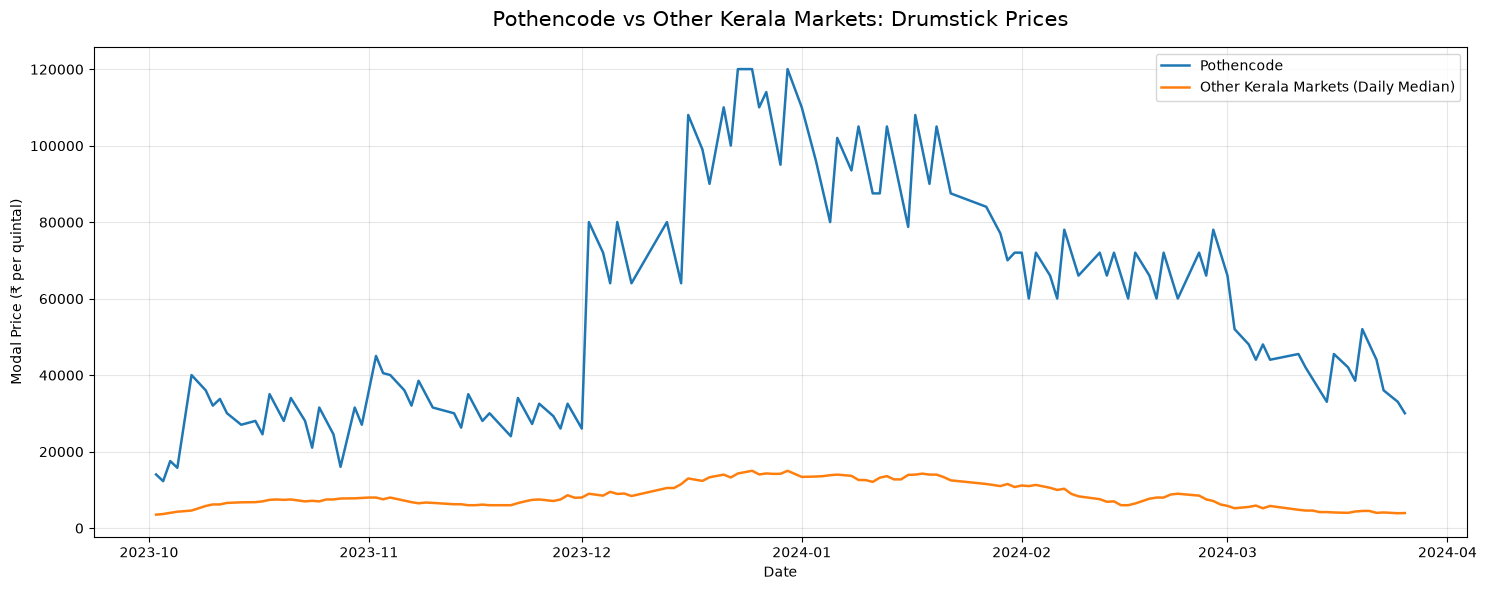

In [44]:
# 7.9 Visualise Pothencode against other Kerala markets

plt.figure(figsize=(15, 6))

plt.plot(
    matched_dates.index,
    matched_dates["Pothencode_Price"],
    label="Pothencode",
    linewidth=1.8
)

plt.plot(
    matched_dates.index,
    matched_dates["Other_Markets_Median"],
    label="Other Kerala Markets (Daily Median)",
    linewidth=1.8
)

plt.title(
    "Pothencode vs Other Kerala Markets: Drumstick Prices",
    fontsize=15,
    pad=15
)

plt.xlabel("Date")
plt.ylabel("Modal Price (₹ per quintal)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.10 Pothencode Drumstick Price Anomaly: Findings

The investigation identified an unusually high price series for Drumstick reported by Pothencode, Thiruvananthapuram, Kerala.

Key findings:

- The dataset contains 1,322 Pothencode Drumstick observations between 2006 and 2026.
- The median modal price is ₹7,500 per quintal, while the maximum reaches ₹1,20,040.
- The most extreme price episode occurs around late 2023 and early 2024.
- Across 137 dates with observations from both Pothencode and other Kerala markets, the median Pothencode price is approximately 6.95 times the median price of other markets.
- Pothencode prices exceed twice the other-market median on all 137 matched dates and exceed five times that median on 101 dates.

**Interpretation:** The persistent discrepancy suggests a market-specific reporting anomaly that warrants further validation.

The available dataset does not establish whether the cause is a data-entry error, unit inconsistency, reporting convention, or genuine market-specific condition. Therefore, these observations should be flagged for investigation rather than automatically deleted or corrected.

**Analytical implication:** Market-level anomaly checks and comparisons with contemporaneous observations from other markets are important before using historical prices for forecasting or selling decisions.

---

# 8. Overall Findings and Conclusion

## 8.1 Key Findings

The exploratory analysis of 30.3 million wholesale price observations across 46 vegetables revealed several important patterns.

### 1. Dataset coverage is highly imbalanced

Potato, Onion, Tomato, Brinjal, and Green Chilli account for a substantial share of the available observations. Historical coverage also varies across vegetables, so analytical reliability is not uniform.

### 2. Reporting activity declined substantially

Comparing November 2024–March 2025 with November 2025–March 2026:

- Total records declined by approximately 77.1%.
- Average active market identities per month declined by approximately 6.4%.
- Records per active market-month declined by approximately 75.5%.

This substantially limits the reliability of recent historical comparisons.

### 3. Wholesale prices have changed over time

Comparisons between 2001–2005 and 2021–2025 show higher pooled median prices for the vegetables with observations in both periods. Matched-market analysis also identifies substantial long-term price differences.

These comparisons are not adjusted for inflation, variety, or grade.

### 4. Recurring seasonal patterns exist

Several vegetables exhibit recurring high- and low-price months. Examples include high seasonal price indices for Drumstick in January and December, and low indices for Green Peas during January and February.

These are historical patterns, not guaranteed future price movements.

### 5. Price volatility differs across vegetables

Rat Tail Radish, Surat Beans, Methi, and Drumstick show relatively high typical monthly price fluctuations.

A substantial proportion of extreme monthly movements occurred under very low reporting coverage, although some also occurred with higher coverage.

### 6. Geographical price variation is substantial

State-level median prices differ across many vegetables. However, differences in reporting coverage, market composition, dates, varieties, and grades limit direct comparisons.

### 7. Market-specific anomalies require investigation

The Pothencode Drumstick series showed persistent prices substantially above those reported by other Kerala markets on matched dates.

The discrepancy warrants validation rather than automatic correction or deletion.

## 8.2 Limitations

- The source dataset ends on 20 April 2026 and is not current enough to represent November 2026 market conditions.
- Reporting activity declines substantially after October 2025.
- Market and commodity coverage is uneven.
- Historical prices are not adjusted for inflation.
- Variety and grade differences can affect price comparisons.
- Monthly aggregation can conceal short-lived price movements.
- Seasonal associations do not establish causation.
- Wholesale modal prices do not represent guaranteed farmgate realisation.
- Suspicious observations cannot always be independently verified using the available dataset.

## 8.3 Conclusion

The exploratory analysis demonstrates that Indian agricultural wholesale prices exhibit substantial temporal, seasonal, geographical, and commodity-level variation.

It also identifies important limitations in reporting coverage and data quality that must be considered before developing reliable market intelligence or forecasting systems.

The findings provide an analytical foundation for the subsequent market-comparison and forecasting modules of MandiMitra.